In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../reports/results")

MODEL_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

In [2]:
with open(DATA_PATH / "feature_metadata.json", "r") as f:
    feature_metadata = json.load(f)

with open(MODEL_PATH / "advanced_model_metadata.json", "r") as f:
    advanced_metadata = json.load(f)

feature_columns = feature_metadata["feature_columns"]
target_column = feature_metadata["target_column"]

model = joblib.load(
    MODEL_PATH / "best_xgboost.joblib"
)

print("Selected model:", advanced_metadata["model_name"])
print("Previous validation AP:",
      advanced_metadata["validation_average_precision"])

Selected model: XGBoost - Shallow - 10% Sample
Previous validation AP: 0.6080079143620549


In [3]:
previous_results = pd.read_csv(
    RESULTS_PATH / "all_model_results.csv"
)

previous_results.head(10)

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives,algorithm,training_time_seconds,best_iteration,training_rows,negative_sample_rate,weighting
0,XGBoost - Shallow - 10% Sample,0.5,0.994200,0.979079,0.150773,0.261307,0.608008,0.968510,0.367950,234,5,226546,1318,xgboost,8.531136,75.0,604778.0,0.10,population
1,XGBoost - Shallow,0.5,0.994546,0.975309,0.203608,0.336887,0.603106,0.969962,0.455257,316,8,226543,1236,xgboost,15.069758,164.0,305142.0,0.05,population
2,XGBoost - Regularized,0.5,0.994029,0.994792,0.123067,0.219037,0.593509,0.967893,0.289049,191,1,226550,1361,xgboost,8.986205,102.0,305142.0,0.05,population
3,LightGBM - Population Weighted,0.5,0.993924,1.000000,0.106959,0.193248,0.590204,0.971202,0.325844,166,0,226551,1386,lightgbm,2.185153,21.0,305142.0,0.05,population
4,XGBoost - Deep,0.5,0.994117,0.990654,0.136598,0.240091,0.589572,0.967772,0.340465,212,2,226549,1340,xgboost,7.882655,57.0,305142.0,0.05,population
5,LightGBM - Slow Learning,0.5,0.993411,1.000000,0.031572,0.061212,0.589129,0.967860,0.096577,49,0,226551,1503,lightgbm,2.347031,36.0,305142.0,0.05,population
6,LightGBM - Deep,0.5,0.993433,1.000000,0.034794,0.067248,0.587081,0.972863,0.106184,54,0,226551,1498,lightgbm,2.964712,16.0,305142.0,0.05,population
7,XGBoost - Slow Learning,0.5,0.994630,0.957983,0.220361,0.358303,0.586666,0.970947,0.467000,342,15,226536,1210,xgboost,16.609640,190.0,305142.0,0.05,population
8,XGBoost - Population Weighted,0.5,0.993998,0.994595,0.118557,0.211860,0.580715,0.966844,0.287200,184,1,226550,1368,xgboost,8.747880,58.0,305142.0,0.05,population
9,XGBoost - Class Balanced,0.5,0.939790,0.092029,0.885309,0.166727,0.580213,0.975219,0.987115,1374,13556,212995,178,xgboost,10.443056,108.0,305142.0,0.05,balanced


In [4]:
load_columns = feature_columns + [
    target_column,
    "step",
    "isFlaggedFraud"
]

val_df = pd.read_parquet(
    DATA_PATH / "validation.parquet",
    columns=load_columns
)

print("Validation shape:", val_df.shape)

Validation shape: (228103, 15)


In [5]:
CALIBRATION_END_STEP = 519

calibration_df = val_df.loc[
    val_df["step"] <= CALIBRATION_END_STEP
].copy()

policy_df = val_df.loc[
    val_df["step"] > CALIBRATION_END_STEP
].copy()

assert (
    calibration_df["step"].max()
    < policy_df["step"].min()
)

assert len(calibration_df) + len(policy_df) == len(val_df)

split_summary = pd.DataFrame([
    {
        "split": "Calibration",
        "start_step": calibration_df["step"].min(),
        "end_step": calibration_df["step"].max(),
        "transactions": len(calibration_df),
        "fraudulent_transactions": calibration_df[target_column].sum(),
        "fraud_rate": calibration_df[target_column].mean()
    },
    {
        "split": "Policy Optimization",
        "start_step": policy_df["step"].min(),
        "end_step": policy_df["step"].max(),
        "transactions": len(policy_df),
        "fraudulent_transactions": policy_df[target_column].sum(),
        "fraud_rate": policy_df[target_column].mean()
    }
])

split_summary

,split,start_step,end_step,transactions,fraudulent_transactions,fraud_rate
0,Calibration,446,519,68033,762,0.011200
1,Policy Optimization,520,594,160070,790,0.004935


In [6]:
X_calibration = calibration_df[feature_columns]
y_calibration = calibration_df[target_column]

X_policy = policy_df[feature_columns]
y_policy = policy_df[target_column]

assert y_calibration.nunique() == 2
assert y_policy.nunique() == 2

In [7]:
calibration_raw_probs = model.predict_proba(
    X_calibration
)[:, 1]

policy_raw_probs = model.predict_proba(
    X_policy
)[:, 1]

pd.Series(policy_raw_probs).describe()

count    160070.000000
mean          0.001676
std           0.023705
min           0.000035
25%           0.000047
50%           0.000090
75%           0.000516
max           0.992667
dtype: float64

In [8]:
EPSILON = 1e-12

def probability_to_logit(probabilities):

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    probabilities = np.clip(
        probabilities,
        EPSILON,
        1 - EPSILON
    )

    return np.log(
        probabilities / (1 - probabilities)
    ).reshape(-1, 1)

In [9]:
calibrator = LogisticRegression(
    C=1000,
    solver="lbfgs",
    max_iter=1000,
    random_state=RANDOM_STATE
)

calibrator.fit(
    probability_to_logit(calibration_raw_probs),
    y_calibration
)

print("Calibration coefficient:",
      calibrator.coef_[0][0])

print("Calibration intercept:",
      calibrator.intercept_[0])

Calibration coefficient: 1.180470208807564
Calibration intercept: 3.0877332054786812


In [10]:
def calibrate_probabilities(probabilities):

    return calibrator.predict_proba(
        probability_to_logit(probabilities)
    )[:, 1]

In [11]:
policy_calibrated_probs = calibrate_probabilities(
    policy_raw_probs
)

pd.DataFrame({
    "original_probability": policy_raw_probs,
    "calibrated_probability": policy_calibrated_probs
}).describe()

,original_probability,calibrated_probability
count,160070.000000,160070.000000
mean,0.001676,0.007388
std,0.023705,0.050349
min,0.000035,0.000121
25%,0.000047,0.000169
50%,0.000090,0.000365
75%,0.000516,0.002881
max,0.992667,0.999861


In [12]:
def evaluate_calibration(
    model_name,
    y_true,
    probabilities
):

    return {
        "model": model_name,
        "average_precision": average_precision_score(
            y_true, probabilities
        ),
        "roc_auc": roc_auc_score(
            y_true, probabilities
        ),
        "brier_score": brier_score_loss(
            y_true, probabilities
        ),
        "log_loss": log_loss(
            y_true, probabilities, labels=[0, 1]
        ),
        "mean_predicted_probability": np.mean(
            probabilities
        ),
        "observed_fraud_rate": np.mean(y_true)
    }

In [13]:
calibration_results = pd.DataFrame([
    evaluate_calibration(
        "Original XGBoost",
        y_policy,
        policy_raw_probs
    ),
    evaluate_calibration(
        "Calibrated XGBoost",
        y_policy,
        policy_calibrated_probs
    )
])

calibration_results.round(6)

,model,average_precision,roc_auc,brier_score,log_loss,mean_predicted_probability,observed_fraud_rate
0,Original XGBoost,0.577365,0.968702,0.003619,0.016727,0.001676,0.004935
1,Calibrated XGBoost,0.577365,0.968702,0.003012,0.013966,0.007388,0.004935


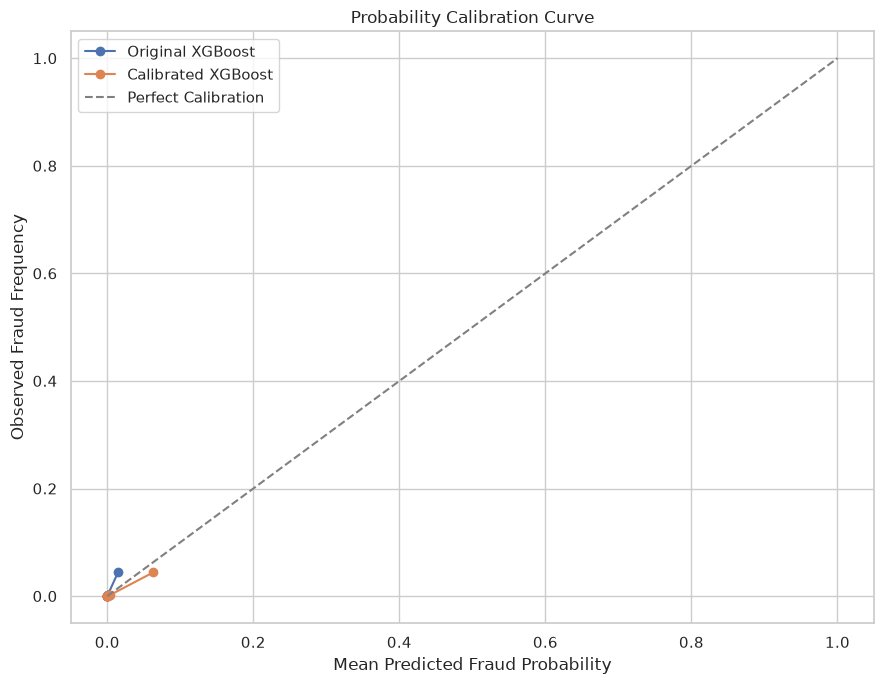

In [14]:
plt.figure(figsize=(9, 7))

for model_name, probabilities in {
    "Original XGBoost": policy_raw_probs,
    "Calibrated XGBoost": policy_calibrated_probs
}.items():

    observed, predicted = calibration_curve(
        y_policy,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted,
        observed,
        marker="o",
        label=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.title("Probability Calibration Curve")
plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Frequency")
plt.legend()
plt.tight_layout()
plt.show()

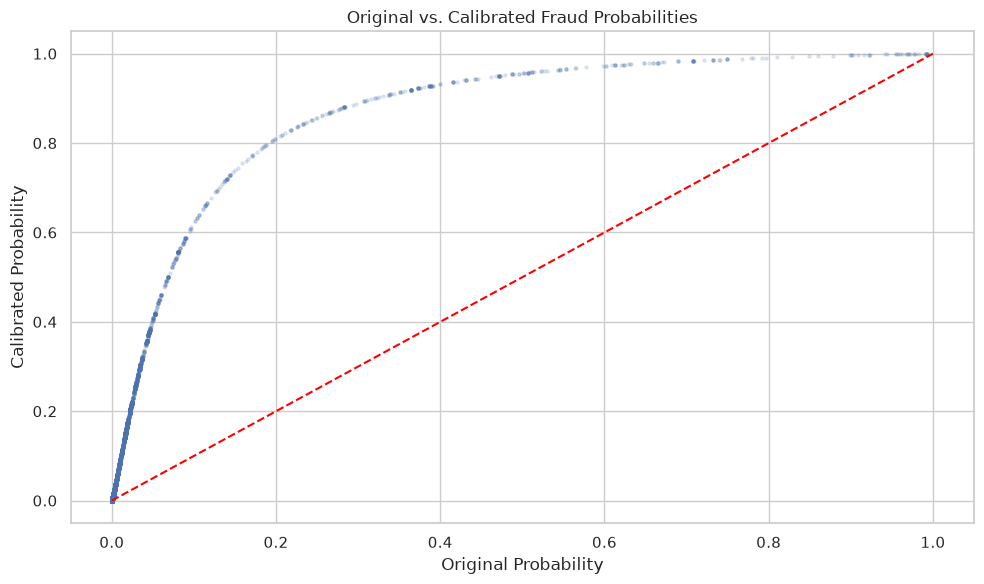

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    policy_raw_probs,
    policy_calibrated_probs,
    alpha=0.15,
    s=5
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red"
)

plt.title("Original vs. Calibrated Fraud Probabilities")
plt.xlabel("Original Probability")
plt.ylabel("Calibrated Probability")
plt.tight_layout()
plt.show()

In [16]:
def evaluate_model(
    model_name,
    y_true,
    probabilities,
    amounts,
    threshold=0.5
):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    amounts = np.asarray(amounts, dtype=np.float64)

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_fraud_amount = amounts[
        y_true == 1
    ].sum()

    detected_fraud_amount = amounts[
        (y_true == 1) & (y_pred == 1)
    ].sum()

    missed_fraud_amount = amounts[
        (y_true == 1) & (y_pred == 0)
    ].sum()

    return {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_true, probabilities
        ),
        "roc_auc": roc_auc_score(
            y_true, probabilities
        ),
        "fraud_value_captured": (
            detected_fraud_amount / total_fraud_amount
            if total_fraud_amount > 0 else 0
        ),
        "detected_fraud_amount": detected_fraud_amount,
        "missed_fraud_amount": missed_fraud_amount,
        "alert_count": int(y_pred.sum()),
        "alert_rate": y_pred.mean(),
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn
    }

In [17]:
default_results = pd.DataFrame([
    evaluate_model(
        "Original XGBoost",
        y_policy,
        policy_raw_probs,
        policy_df["amount"],
        threshold=0.5
    ),
    evaluate_model(
        "Calibrated XGBoost",
        y_policy,
        policy_calibrated_probs,
        policy_df["amount"],
        threshold=0.5
    )
])

default_results.round(6)

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,fraud_value_captured,detected_fraud_amount,missed_fraud_amount,alert_count,alert_rate,true_positives,false_positives,true_negatives,false_negatives
0,Original XGBoost,0.5,0.995783,0.975207,0.149367,0.259056,0.577365,0.968702,0.374129,3.488997e+08,5.836651e+08,121,0.000756,118,3,159277,672
1,Calibrated XGBoost,0.5,0.996633,0.803874,0.420253,0.551953,0.577365,0.968702,0.641788,5.985086e+08,3.340562e+08,413,0.002580,332,81,159199,458


In [18]:
def create_threshold_table(
    y_true,
    probabilities,
    amounts
):

    y_true = np.asarray(y_true, dtype=np.int64)
    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )
    amounts = np.asarray(amounts, dtype=np.float64)

    order = np.argsort(
        -probabilities,
        kind="stable"
    )

    sorted_probs = probabilities[order]
    sorted_labels = y_true[order]
    sorted_amounts = amounts[order]

    cumulative_tp = np.cumsum(sorted_labels)
    cumulative_fp = np.cumsum(1 - sorted_labels)

    cumulative_fraud_amount = np.cumsum(
        sorted_amounts * sorted_labels
    )

    # Evaluate only at distinct score boundaries
    boundaries = np.flatnonzero(
        np.r_[sorted_probs[:-1] != sorted_probs[1:], True]
    )

    total_fraud = y_true.sum()
    total_legitimate = len(y_true) - total_fraud

    total_fraud_amount = amounts[
        y_true == 1
    ].sum()

    # Include a threshold that flags no transactions
    thresholds = np.r_[
        np.nextafter(1.0, np.inf),
        sorted_probs[boundaries]
    ]

    tp = np.r_[0, cumulative_tp[boundaries]]
    fp = np.r_[0, cumulative_fp[boundaries]]

    detected_amount = np.r_[
        0.0,
        cumulative_fraud_amount[boundaries]
    ]

    alerts = tp + fp

    precision = np.divide(
        tp,
        alerts,
        out=np.zeros(len(tp), dtype=float),
        where=alerts > 0
    )

    recall = tp / total_fraud

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(len(tp), dtype=float),
        where=(precision + recall) > 0
    )

    return pd.DataFrame({
        "threshold": thresholds,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "alert_count": alerts,
        "alert_rate": alerts / len(y_true),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": total_fraud - tp,
        "true_negatives": total_legitimate - fp,
        "detected_fraud_amount": detected_amount,
        "missed_fraud_amount": (
            total_fraud_amount - detected_amount
        ),
        "fraud_value_captured": (
            detected_amount / total_fraud_amount
        )
    })

In [19]:
threshold_results = create_threshold_table(
    y_policy,
    policy_calibrated_probs,
    policy_df["amount"]
)

threshold_results.head()

,threshold,precision,recall,f1,alert_count,alert_rate,true_positives,false_positives,false_negatives,true_negatives,detected_fraud_amount,missed_fraud_amount,fraud_value_captured
0,1.000000,0.0,0.000000,0.000000,0,0.000000,0,0,790,159280,0.00,9.325648e+08,0.000000
1,0.999861,1.0,0.006329,0.012579,5,0.000031,5,0,785,159280,18051686.19,9.145131e+08,0.019357
2,0.999821,1.0,0.011392,0.022528,9,0.000056,9,0,781,159280,53748295.73,8.788165e+08,0.057635
3,0.999797,1.0,0.012658,0.025000,10,0.000062,10,0,780,159280,56310755.29,8.762540e+08,0.060383
4,0.999634,1.0,0.013924,0.027466,11,0.000069,11,0,779,159280,59882563.02,8.726822e+08,0.064213


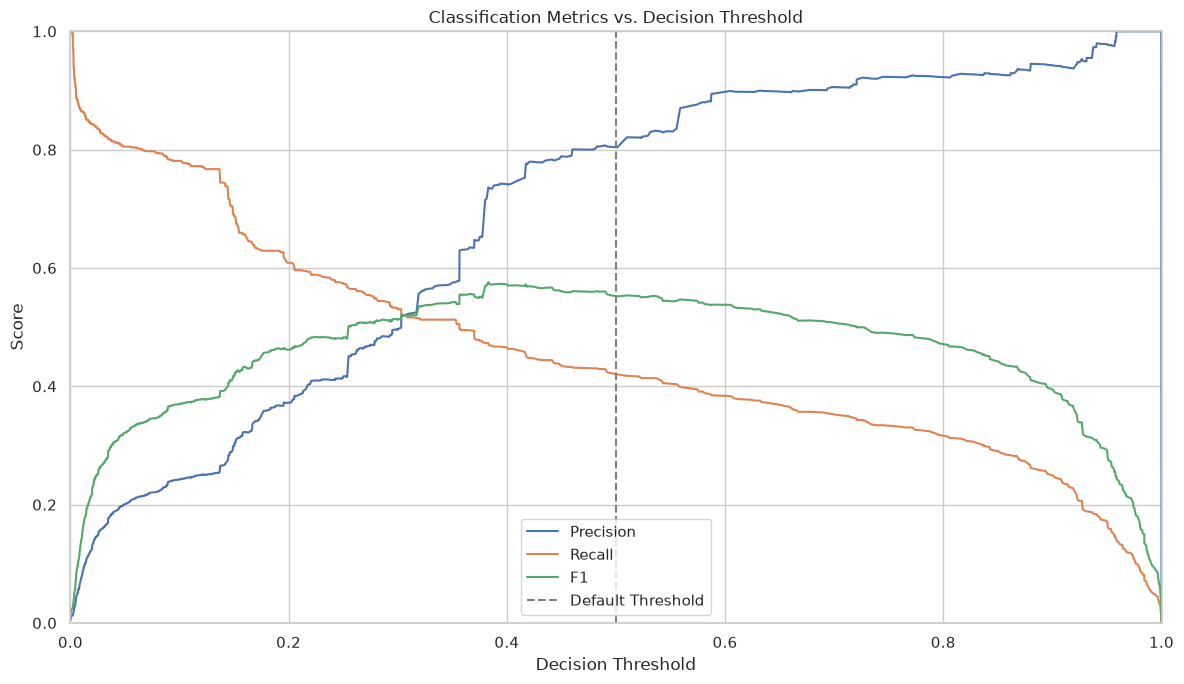

In [20]:
plt.figure(figsize=(12, 7))

for metric in ["precision", "recall", "f1"]:

    plt.plot(
        threshold_results["threshold"],
        threshold_results[metric],
        label=metric.capitalize()
    )

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default Threshold"
)

plt.title("Classification Metrics vs. Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
best_f1_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

best_f1_threshold = float(
    best_f1_row["threshold"]
)

best_f1_row

threshold                3.831532e-01
precision                7.362205e-01
recall                   4.734177e-01
f1                       5.762712e-01
alert_count              5.080000e+02
alert_rate               3.173612e-03
true_positives           3.740000e+02
false_positives          1.340000e+02
false_negatives          4.160000e+02
true_negatives           1.591460e+05
detected_fraud_amount    6.770781e+08
missed_fraud_amount      2.554867e+08
fraud_value_captured     7.260387e-01
Name: 296, dtype: float64

In [22]:
INVESTIGATION_COST = 100.0
PREVENTABLE_FRAUD_FRACTION = 0.10
MAX_ALERT_RATE = 0.01

In [23]:
def calculate_financial_costs(
    threshold_table,
    investigation_cost,
    preventable_fraction
):

    result = threshold_table.copy()

    result["investigation_cost"] = (
        result["alert_count"]
        * investigation_cost
    )

    result["missed_fraud_cost"] = (
        result["missed_fraud_amount"]
        * preventable_fraction
    )

    result["total_cost"] = (
        result["investigation_cost"]
        + result["missed_fraud_cost"]
    )

    no_detection_cost = (
        result.iloc[0]["missed_fraud_amount"]
        * preventable_fraction
    )

    result["estimated_savings"] = (
        no_detection_cost - result["total_cost"]
    )

    return result

In [24]:
cost_results = calculate_financial_costs(
    threshold_results,
    INVESTIGATION_COST,
    PREVENTABLE_FRAUD_FRACTION
)

cost_results.head()

,threshold,precision,recall,f1,alert_count,alert_rate,true_positives,false_positives,false_negatives,true_negatives,detected_fraud_amount,missed_fraud_amount,fraud_value_captured,investigation_cost,missed_fraud_cost,total_cost,estimated_savings
0,1.000000,0.0,0.000000,0.000000,0,0.000000,0,0,790,159280,0.00,9.325648e+08,0.000000,0.0,9.325648e+07,9.325648e+07,0.000
1,0.999861,1.0,0.006329,0.012579,5,0.000031,5,0,785,159280,18051686.19,9.145131e+08,0.019357,500.0,9.145131e+07,9.145181e+07,1804668.619
2,0.999821,1.0,0.011392,0.022528,9,0.000056,9,0,781,159280,53748295.73,8.788165e+08,0.057635,900.0,8.788165e+07,8.788255e+07,5373929.573
3,0.999797,1.0,0.012658,0.025000,10,0.000062,10,0,780,159280,56310755.29,8.762540e+08,0.060383,1000.0,8.762540e+07,8.762640e+07,5630075.529
4,0.999634,1.0,0.013924,0.027466,11,0.000069,11,0,779,159280,59882563.02,8.726822e+08,0.064213,1100.0,8.726822e+07,8.726932e+07,5987156.302


In [25]:
best_cost_row = cost_results.loc[
    cost_results["total_cost"].idxmin()
]

best_cost_threshold = float(
    best_cost_row["threshold"]
)

best_cost_row

threshold                1.177321e-02
precision                9.076412e-02
recall                   8.645570e-01
f1                       1.642814e-01
alert_count              7.525000e+03
alert_rate               4.701068e-02
true_positives           6.830000e+02
false_positives          6.842000e+03
false_negatives          1.070000e+02
true_negatives           1.524380e+05
detected_fraud_amount    9.170324e+08
missed_fraud_amount      1.553242e+07
fraud_value_captured     9.833444e-01
investigation_cost       7.525000e+05
missed_fraud_cost        1.553242e+06
total_cost               2.305742e+06
estimated_savings        9.095074e+07
Name: 2212, dtype: float64

In [26]:
feasible_thresholds = cost_results.loc[
    cost_results["alert_rate"] <= MAX_ALERT_RATE
]

best_constrained_row = feasible_thresholds.loc[
    feasible_thresholds["total_cost"].idxmin()
]

optimal_threshold = float(
    best_constrained_row["threshold"]
)

best_constrained_row

threshold                1.616814e-01
precision                3.224592e-01
recall                   6.506329e-01
f1                       4.312081e-01
alert_count              1.594000e+03
alert_rate               9.958143e-03
true_positives           5.140000e+02
false_positives          1.080000e+03
false_negatives          2.760000e+02
true_negatives           1.582000e+05
detected_fraud_amount    8.671688e+08
missed_fraud_amount      6.539604e+07
fraud_value_captured     9.298751e-01
investigation_cost       1.594000e+05
missed_fraud_cost        6.539604e+06
total_cost               6.699004e+06
estimated_savings        8.655748e+07
Name: 508, dtype: float64

In [27]:
print(f"Default threshold: {0.5:.6f}")
print(f"Best F1 threshold: {best_f1_threshold:.6f}")
print(f"Unconstrained cost threshold: {best_cost_threshold:.6f}")
print(f"Constrained cost threshold: {optimal_threshold:.6f}")

Default threshold: 0.500000
Best F1 threshold: 0.383153
Unconstrained cost threshold: 0.011773
Constrained cost threshold: 0.161681


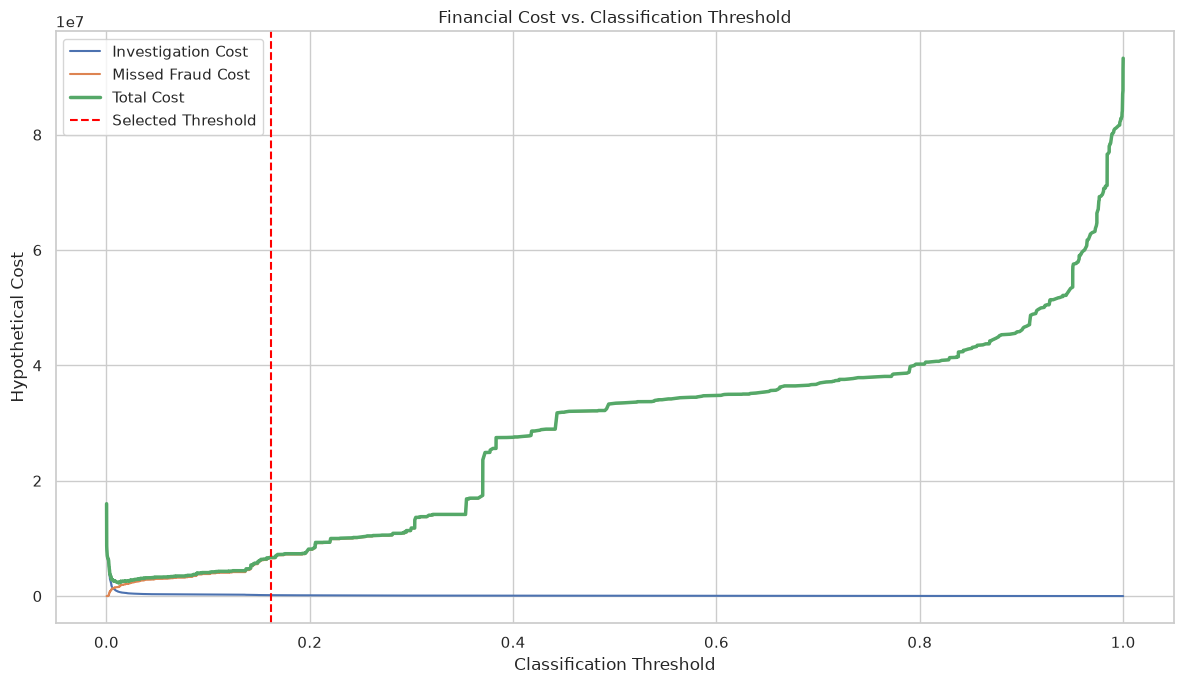

In [28]:
plt.figure(figsize=(12, 7))

plt.plot(
    cost_results["threshold"],
    cost_results["investigation_cost"],
    label="Investigation Cost"
)

plt.plot(
    cost_results["threshold"],
    cost_results["missed_fraud_cost"],
    label="Missed Fraud Cost"
)

plt.plot(
    cost_results["threshold"],
    cost_results["total_cost"],
    label="Total Cost",
    linewidth=2.5
)

plt.axvline(
    optimal_threshold,
    color="red",
    linestyle="--",
    label="Selected Threshold"
)

plt.title("Financial Cost vs. Classification Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("Hypothetical Cost")
plt.legend()
plt.tight_layout()
plt.show()

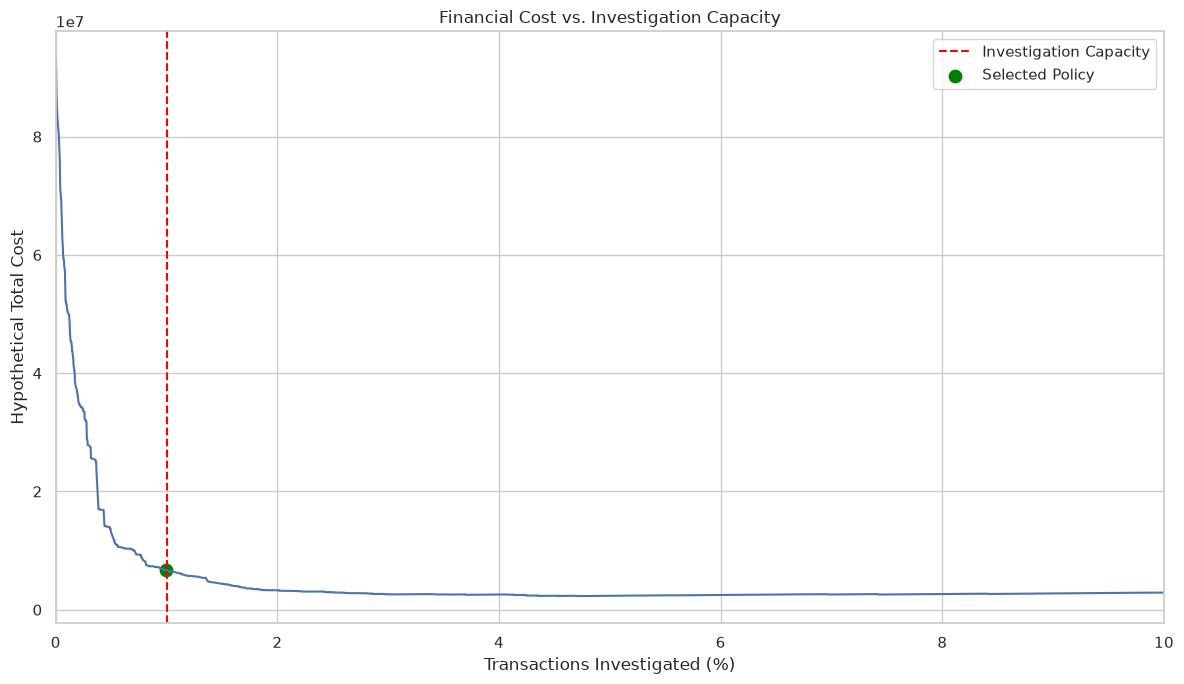

In [29]:
plt.figure(figsize=(12, 7))

plt.plot(
    cost_results["alert_rate"] * 100,
    cost_results["total_cost"]
)

plt.axvline(
    MAX_ALERT_RATE * 100,
    color="red",
    linestyle="--",
    label="Investigation Capacity"
)

plt.scatter(
    best_constrained_row["alert_rate"] * 100,
    best_constrained_row["total_cost"],
    color="green",
    s=80,
    label="Selected Policy"
)

plt.title("Financial Cost vs. Investigation Capacity")
plt.xlabel("Transactions Investigated (%)")
plt.ylabel("Hypothetical Total Cost")
plt.xlim(0, 10)
plt.legend()
plt.tight_layout()
plt.show()

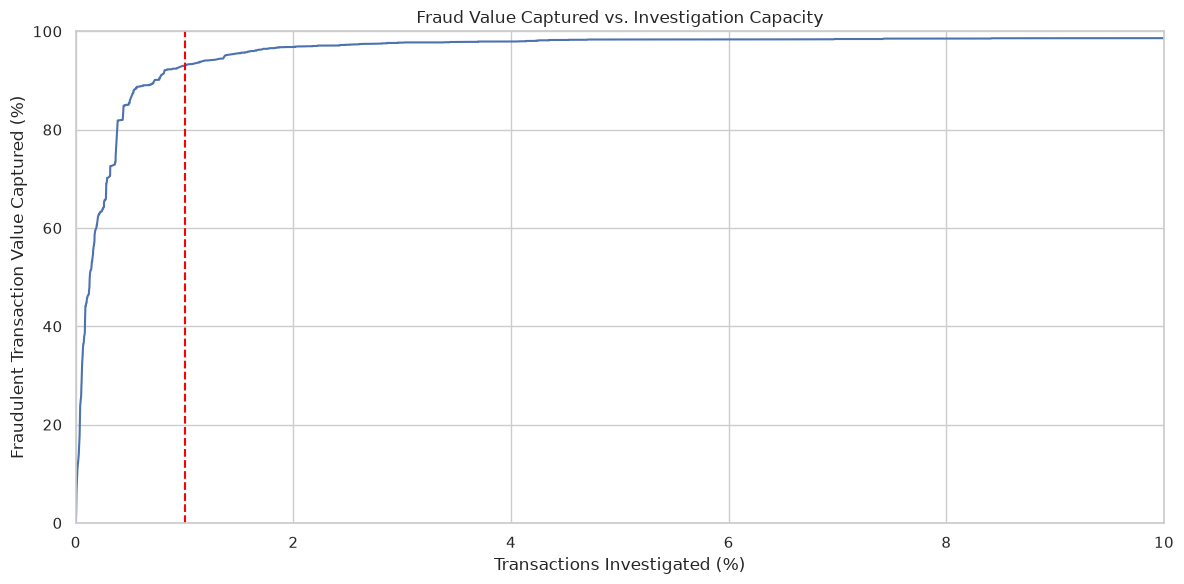

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(
    cost_results["alert_rate"] * 100,
    cost_results["fraud_value_captured"] * 100
)

plt.axvline(
    MAX_ALERT_RATE * 100,
    color="red",
    linestyle="--"
)

plt.title("Fraud Value Captured vs. Investigation Capacity")
plt.xlabel("Transactions Investigated (%)")
plt.ylabel("Fraudulent Transaction Value Captured (%)")
plt.xlim(0, 10)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [31]:
decision_policies = {
    "No Detection": np.nextafter(1.0, np.inf),
    "Default Threshold": 0.5,
    "Maximum F1": best_f1_threshold,
    "Minimum Cost": best_cost_threshold,
    "Capacity-Constrained Minimum Cost": optimal_threshold
}

In [32]:
def evaluate_decision_policy(
    policy_name,
    y_true,
    probabilities,
    amounts,
    threshold
):

    metrics = evaluate_model(
        policy_name,
        y_true,
        probabilities,
        amounts,
        threshold
    )

    metrics["investigation_cost"] = (
        metrics["alert_count"] * INVESTIGATION_COST
    )

    metrics["missed_fraud_cost"] = (
        metrics["missed_fraud_amount"]
        * PREVENTABLE_FRAUD_FRACTION
    )

    metrics["total_cost"] = (
        metrics["investigation_cost"]
        + metrics["missed_fraud_cost"]
    )

    no_detection_cost = (
        np.asarray(amounts)[np.asarray(y_true) == 1].sum()
        * PREVENTABLE_FRAUD_FRACTION
    )

    metrics["estimated_savings"] = (
        no_detection_cost - metrics["total_cost"]
    )

    return metrics

In [33]:
policy_results = pd.DataFrame([
    evaluate_decision_policy(
        policy_name,
        y_policy,
        policy_calibrated_probs,
        policy_df["amount"],
        threshold
    )
    for policy_name, threshold in decision_policies.items()
])

policy_comparison_columns = [
    "model",
    "threshold",
    "precision",
    "recall",
    "f1",
    "alert_rate",
    "false_positives",
    "fraud_value_captured",
    "total_cost",
    "estimated_savings"
]

policy_results[
    policy_comparison_columns
].round(6)

,model,threshold,precision,recall,f1,alert_rate,false_positives,fraud_value_captured,total_cost,estimated_savings
0,No Detection,1.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,9.325648e+07,0.000000e+00
1,Default Threshold,0.500000,0.803874,0.420253,0.551953,0.002580,81,0.641788,3.344692e+07,5.980956e+07
2,Maximum F1,0.383153,0.736220,0.473418,0.576271,0.003174,134,0.726039,2.559947e+07,6.765701e+07
3,Minimum Cost,0.011773,0.090764,0.864557,0.164281,0.047011,6842,0.983344,2.305742e+06,9.095074e+07
4,Capacity-Constrained Minimum Cost,0.161681,0.322459,0.650633,0.431208,0.009958,1080,0.929875,6.699004e+06,8.655748e+07


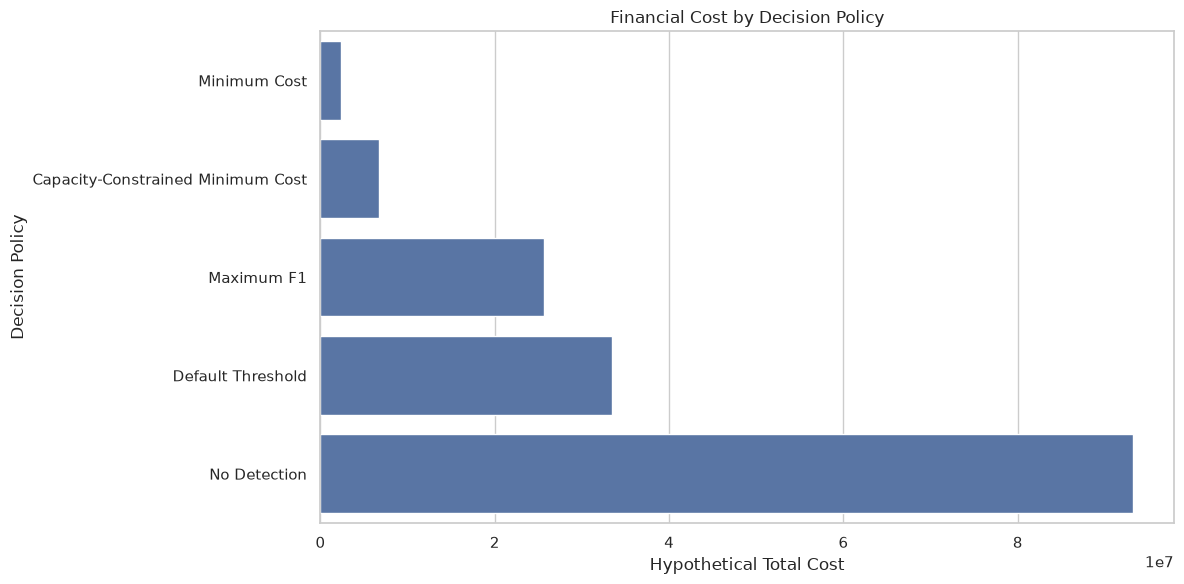

In [34]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=policy_results.sort_values("total_cost"),
    x="total_cost",
    y="model"
)

plt.title("Financial Cost by Decision Policy")
plt.xlabel("Hypothetical Total Cost")
plt.ylabel("Decision Policy")
plt.tight_layout()
plt.show()

In [35]:
investigation_costs = [
    10,
    50,
    100,
    500,
    1000
]

preventable_fractions = [
    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    1.00
]

In [36]:
sensitivity_results = []

for investigation_cost in investigation_costs:

    for preventable_fraction in preventable_fractions:

        scenario = calculate_financial_costs(
            threshold_results,
            investigation_cost,
            preventable_fraction
        )

        feasible = scenario.loc[
            scenario["alert_rate"] <= MAX_ALERT_RATE
        ]

        best_row = feasible.loc[
            feasible["total_cost"].idxmin()
        ]

        sensitivity_results.append({
            "investigation_cost": investigation_cost,
            "preventable_fraction": preventable_fraction,
            "optimal_threshold": best_row["threshold"],
            "alert_rate": best_row["alert_rate"],
            "precision": best_row["precision"],
            "recall": best_row["recall"],
            "fraud_value_captured": best_row[
                "fraud_value_captured"
            ],
            "total_cost": best_row["total_cost"],
            "estimated_savings": best_row[
                "estimated_savings"
            ]
        })

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

sensitivity_df.round(6)

,investigation_cost,preventable_fraction,optimal_threshold,alert_rate,precision,recall,fraud_value_captured,total_cost,estimated_savings
0,10,0.01,0.161681,0.009958,0.322459,0.650633,0.929875,6.699004e+05,8.655748e+06
1,10,0.05,0.161681,0.009958,0.322459,0.650633,0.929875,3.285742e+06,4.334250e+07
2,10,0.10,0.161681,0.009958,0.322459,0.650633,0.929875,6.555544e+06,8.670094e+07
3,10,0.25,0.161681,0.009958,0.322459,0.650633,0.929875,1.636495e+07,2.167763e+08
4,10,0.50,0.161681,0.009958,0.322459,0.650633,0.929875,3.271396e+07,4.335684e+08
5,10,1.00,0.161681,0.009958,0.322459,0.650633,0.929875,6.541198e+07,8.671528e+08
6,50,0.01,0.165959,0.009802,0.324410,0.644304,0.929769,7.333967e+05,8.592251e+06
7,50,0.05,0.161681,0.009958,0.322459,0.650633,0.929875,3.349502e+06,4.327874e+07
8,50,0.10,0.161681,0.009958,0.322459,0.650633,0.929875,6.619304e+06,8.663718e+07
9,50,0.25,0.161681,0.009958,0.322459,0.650633,0.929875,1.642871e+07,2.167125e+08


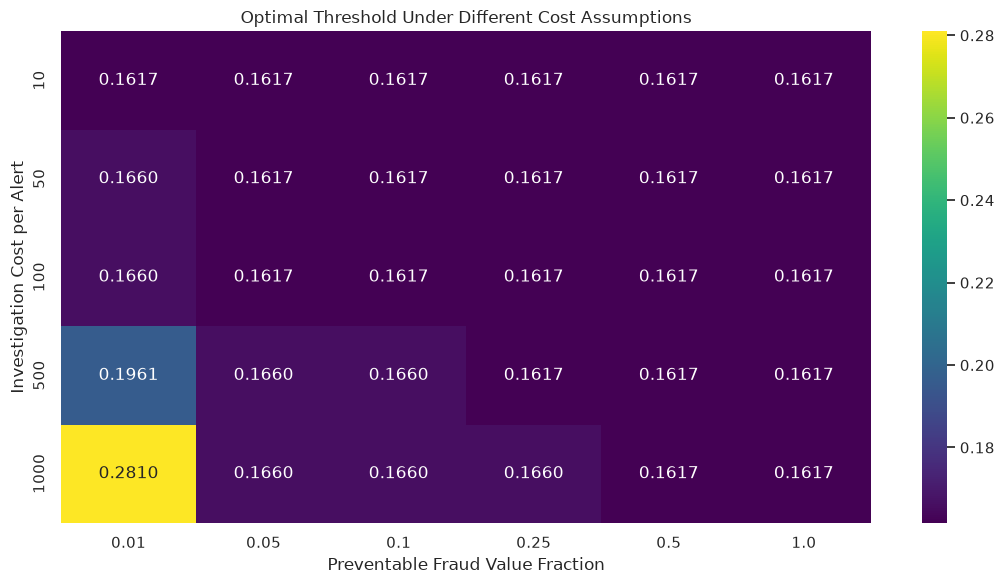

In [37]:
threshold_heatmap = sensitivity_df.pivot(
    index="investigation_cost",
    columns="preventable_fraction",
    values="optimal_threshold"
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    threshold_heatmap,
    annot=True,
    fmt=".4f",
    cmap="viridis"
)

plt.title("Optimal Threshold Under Different Cost Assumptions")
plt.xlabel("Preventable Fraud Value Fraction")
plt.ylabel("Investigation Cost per Alert")
plt.tight_layout()
plt.show()

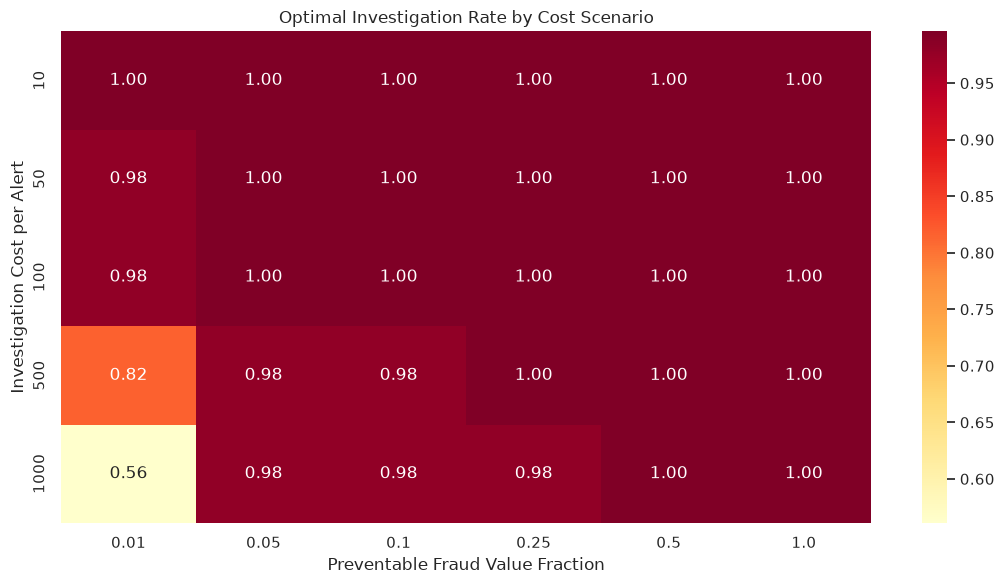

In [38]:
alert_heatmap = sensitivity_df.pivot(
    index="investigation_cost",
    columns="preventable_fraction",
    values="alert_rate"
) * 100

plt.figure(figsize=(11, 6))

sns.heatmap(
    alert_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Optimal Investigation Rate by Cost Scenario")
plt.xlabel("Preventable Fraud Value Fraction")
plt.ylabel("Investigation Cost per Alert")
plt.tight_layout()
plt.show()

In [39]:
HIGH_RISK_ALERT_RATE = 0.001

high_risk_candidates = threshold_results.loc[
    threshold_results["alert_rate"] <= HIGH_RISK_ALERT_RATE
]

high_risk_row = high_risk_candidates.loc[
    high_risk_candidates["alert_count"].idxmax()
]

medium_risk_threshold = optimal_threshold

high_risk_threshold = max(
    medium_risk_threshold,
    float(high_risk_row["threshold"])
)

print("Medium Risk Threshold:", medium_risk_threshold)
print("High Risk Threshold:", high_risk_threshold)

Medium Risk Threshold: 0.16168135726258814
High Risk Threshold: 0.9279876292913652


In [40]:
def assign_risk_tier(
    probabilities,
    medium_threshold,
    high_threshold
):

    probabilities = np.asarray(probabilities)

    return np.select(
        [
            probabilities >= high_threshold,
            probabilities >= medium_threshold
        ],
        [
            "High Risk",
            "Medium Risk"
        ],
        default="Low Risk"
    )

In [41]:
policy_df["fraud_probability"] = (
    policy_calibrated_probs
)

policy_df["risk_tier"] = assign_risk_tier(
    policy_calibrated_probs,
    medium_risk_threshold,
    high_risk_threshold
)

policy_df["risk_tier"].value_counts()

risk_tier
Low Risk       158476
Medium Risk      1434
High Risk         160
Name: count, dtype: int64

In [42]:
def summarize_risk_tiers(dataset):

    summary = dataset.groupby("risk_tier").agg(
        transactions=(target_column, "count"),
        fraudulent_transactions=(target_column, "sum"),
        average_probability=("fraud_probability", "mean"),
        total_transaction_amount=("amount", "sum")
    )

    summary["fraud_rate"] = (
        summary["fraudulent_transactions"]
        / summary["transactions"]
    )

    fraud_amounts = (
        dataset.loc[dataset[target_column] == 1]
        .groupby("risk_tier")["amount"]
        .sum()
    )

    summary["fraudulent_amount"] = (
        fraud_amounts.reindex(summary.index)
        .fillna(0)
    )

    summary["transaction_percentage"] = (
        summary["transactions"] / len(dataset)
    )

    return summary.reindex([
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ])

In [43]:
risk_tier_summary = summarize_risk_tiers(
    policy_df
)

risk_tier_summary

,transactions,fraudulent_transactions,average_probability,total_transaction_amount,fraud_rate,fraudulent_amount,transaction_percentage
risk_tier,,,,,,,
Low Risk,158476,276,0.003289,2.424661e+10,0.001742,6.539604e+07,0.990042
Medium Risk,1434,362,0.352623,1.404397e+09,0.252441,4.478008e+08,0.008959
High Risk,160,152,0.973106,4.219220e+08,0.950000,4.193680e+08,0.001000


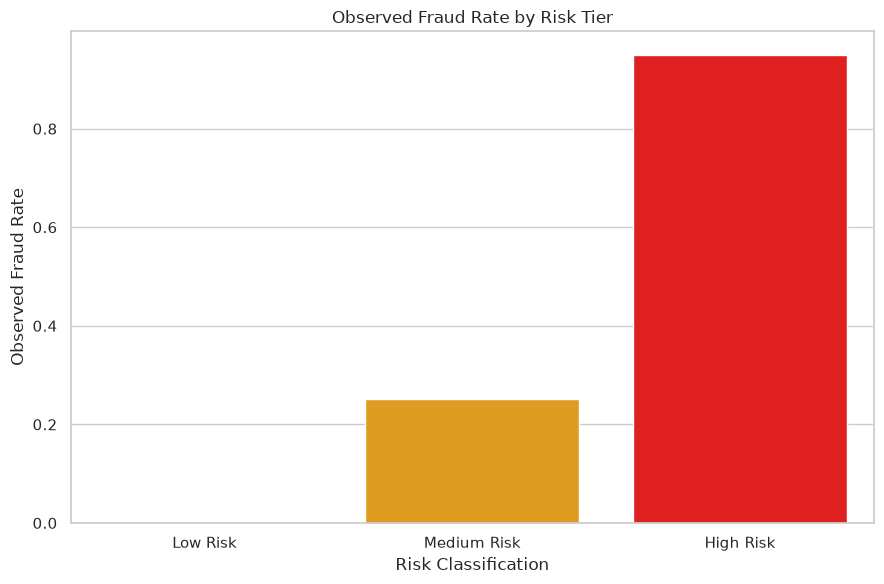

In [44]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=risk_tier_summary.reset_index(),
    x="risk_tier",
    y="fraud_rate",
    hue="risk_tier",
    palette={
        "Low Risk": "green",
        "Medium Risk": "orange",
        "High Risk": "red"
    },
    legend=False
)

plt.title("Observed Fraud Rate by Risk Tier")
plt.xlabel("Risk Classification")
plt.ylabel("Observed Fraud Rate")
plt.tight_layout()
plt.show()

In [45]:
final_model_artifact = {
    "model": model,
    "calibrator": calibrator,
    "feature_columns": feature_columns,
    "logit_epsilon": EPSILON,
    "decision_threshold": medium_risk_threshold,
    "high_risk_threshold": high_risk_threshold
}

joblib.dump(
    final_model_artifact,
    MODEL_PATH / "final_fraud_model.joblib"
)

['../models/final_fraud_model.joblib']

In [46]:
decision_policy = {
    "model_name": advanced_metadata["model_name"],
    "model_type": "XGBoost",
    "calibration_method": "sigmoid_logit",
    "calibration_coefficient": float(
        calibrator.coef_[0][0]
    ),
    "calibration_intercept": float(
        calibrator.intercept_[0]
    ),
    "logit_epsilon": EPSILON,
    "calibration_end_step": CALIBRATION_END_STEP,
    "policy_start_step": int(
        policy_df["step"].min()
    ),
    "policy_end_step": int(
        policy_df["step"].max()
    ),
    "decision_threshold": medium_risk_threshold,
    "high_risk_threshold": high_risk_threshold,
    "threshold_selection_method": (
        "capacity_constrained_cost_minimization"
    ),
    "investigation_cost": INVESTIGATION_COST,
    "preventable_fraud_fraction": (
        PREVENTABLE_FRAUD_FRACTION
    ),
    "maximum_policy_alert_rate": MAX_ALERT_RATE,
    "high_risk_alert_rate": HIGH_RISK_ALERT_RATE,
    "cost_assumptions": "hypothetical",
    "policy_frozen_before_test": True,
    "feature_columns": feature_columns,
    "random_state": RANDOM_STATE
}

with open(
    MODEL_PATH / "decision_policy.json",
    "w"
) as f:

    json.dump(
        decision_policy,
        f,
        indent=4
    )

In [47]:
calibration_results.to_csv(
    RESULTS_PATH / "calibration_results.csv",
    index=False
)

policy_results.to_csv(
    RESULTS_PATH / "decision_policy_results.csv",
    index=False
)

sensitivity_df.to_csv(
    RESULTS_PATH / "cost_sensitivity_results.csv",
    index=False
)

risk_tier_summary.to_csv(
    RESULTS_PATH / "policy_risk_tier_results.csv"
)

In [48]:
test_df = pd.read_parquet(
    DATA_PATH / "test.parquet",
    columns=load_columns
)

print("Test shape:", test_df.shape)
print("Test fraud rate:", test_df[target_column].mean())

assert (
    test_df["step"].min()
    > policy_df["step"].max()
)

X_test = test_df[feature_columns]
y_test = test_df[target_column]

Test shape: (123580, 15)
Test fraud rate: 0.01338404272536009


In [49]:
final_artifact = joblib.load(
    MODEL_PATH / "final_fraud_model.joblib"
)

In [50]:
test_raw_probs = final_artifact[
    "model"
].predict_proba(
    X_test[final_artifact["feature_columns"]]
)[:, 1]

test_calibrated_probs = final_artifact[
    "calibrator"
].predict_proba(
    probability_to_logit(test_raw_probs)
)[:, 1]

final_threshold = final_artifact[
    "decision_threshold"
]

final_high_risk_threshold = final_artifact[
    "high_risk_threshold"
]

test_predictions = (
    test_calibrated_probs >= final_threshold
).astype(int)

test_df["fraud_probability"] = test_calibrated_probs

test_df["risk_tier"] = assign_risk_tier(
    test_calibrated_probs,
    final_threshold,
    final_high_risk_threshold
)

In [51]:
final_test_metrics = evaluate_decision_policy(
    "Final XGBoost",
    y_test,
    test_calibrated_probs,
    test_df["amount"],
    final_threshold
)

pd.Series(final_test_metrics)

model                    Final XGBoost
threshold                     0.161681
accuracy                      0.988145
precision                     0.550346
recall                        0.624547
f1                            0.585103
average_precision             0.674554
roc_auc                       0.966435
fraud_value_captured          0.939845
detected_fraud_amount    2558666443.67
missed_fraud_amount       163768125.69
alert_count                       1877
alert_rate                    0.015189
true_positives                    1033
false_positives                    844
true_negatives                  121082
false_negatives                    621
investigation_cost            187700.0
missed_fraud_cost         16376812.569
total_cost                16564512.569
estimated_savings        255678944.367
dtype: object

In [52]:
test_results = pd.DataFrame([
    evaluate_decision_policy(
        "Original XGBoost - Default Threshold",
        y_test,
        test_raw_probs,
        test_df["amount"],
        0.5
    ),
    evaluate_decision_policy(
        "Calibrated XGBoost - Default Threshold",
        y_test,
        test_calibrated_probs,
        test_df["amount"],
        0.5
    ),
    final_test_metrics,
    evaluate_decision_policy(
        "PaySim Fraud Rule",
        y_test,
        test_df["isFlaggedFraud"].to_numpy(),
        test_df["amount"],
        0.5
    )
])

test_results[
    policy_comparison_columns
].round(6)

,model,threshold,precision,recall,f1,alert_rate,false_positives,fraud_value_captured,total_cost,estimated_savings
0,Original XGBoost - Default Threshold,0.500000,0.996587,0.176542,0.299949,0.002371,1,0.457234,1.477938e+08,1.244497e+08
1,Calibrated XGBoost - Default Threshold,0.500000,0.889163,0.436518,0.585564,0.006571,90,0.756299,6.642730e+07,2.058162e+08
2,Final XGBoost,0.161681,0.550346,0.624547,0.585103,0.015189,844,0.939845,1.656451e+07,2.556789e+08
3,PaySim Fraud Rule,0.500000,1.000000,0.004837,0.009627,0.000065,0,0.015627,2.679898e+08,4.253664e+06


In [53]:
actual_test_alert_rate = final_test_metrics[
    "alert_rate"
]

print(
    f"Target alert rate: {MAX_ALERT_RATE:.2%}"
)

print(
    f"Observed test alert rate: {actual_test_alert_rate:.2%}"
)

print(
    "Capacity target satisfied:",
    actual_test_alert_rate <= MAX_ALERT_RATE
)

Target alert rate: 1.00%
Observed test alert rate: 1.52%
Capacity target satisfied: False


In [54]:
final_policy_metrics = evaluate_decision_policy(
    "Policy Optimization",
    y_policy,
    policy_calibrated_probs,
    policy_df["amount"],
    final_threshold
)

comparison_df = pd.DataFrame([
    final_policy_metrics,
    {
        **final_test_metrics,
        "model": "Held-Out Test"
    }
])

comparison_df[[
    "model",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "alert_rate",
    "fraud_value_captured",
    "false_positives"
]].round(6)

,model,average_precision,roc_auc,precision,recall,f1,alert_rate,fraud_value_captured,false_positives
0,Policy Optimization,0.577365,0.968702,0.322459,0.650633,0.431208,0.009958,0.929875,1080
1,Held-Out Test,0.674554,0.966435,0.550346,0.624547,0.585103,0.015189,0.939845,844


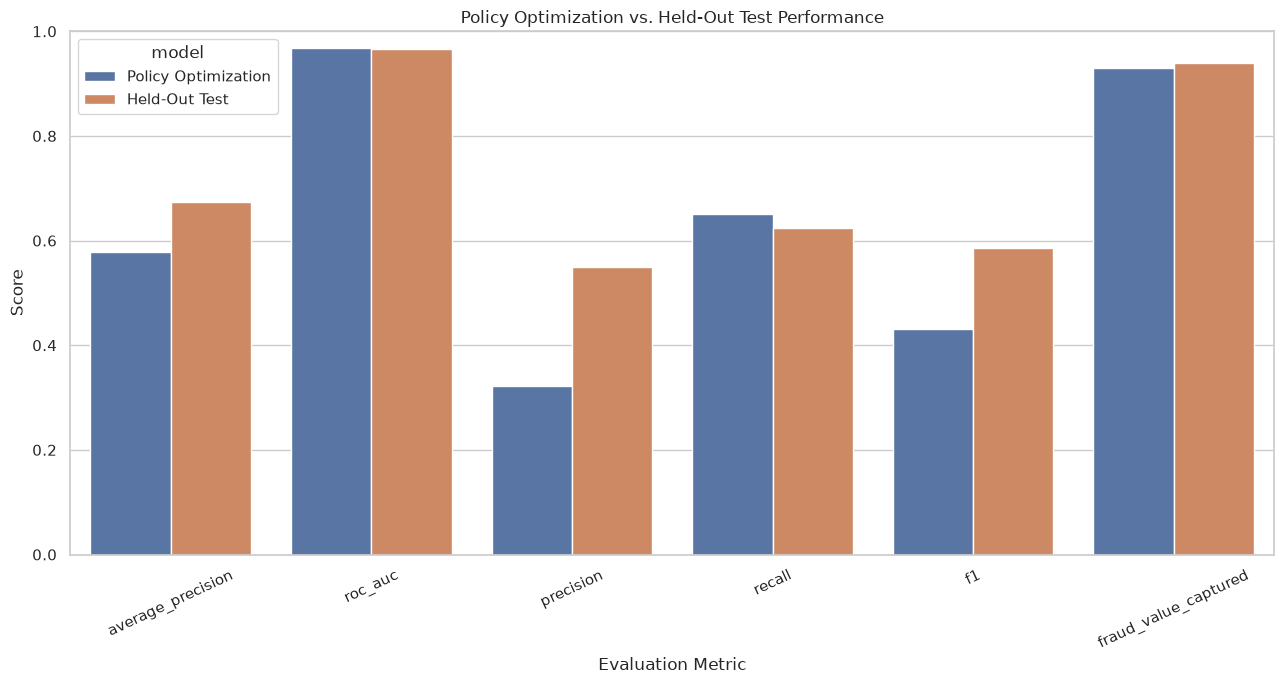

In [55]:
comparison_plot = comparison_df.melt(
    id_vars="model",
    value_vars=[
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "fraud_value_captured"
    ],
    var_name="metric",
    value_name="score"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=comparison_plot,
    x="metric",
    y="score",
    hue="model"
)

plt.title("Policy Optimization vs. Held-Out Test Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

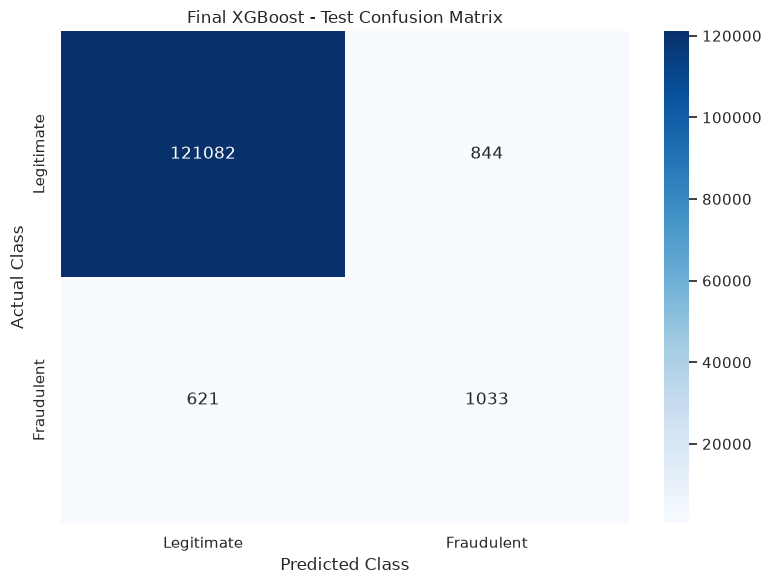

In [56]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Final XGBoost - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

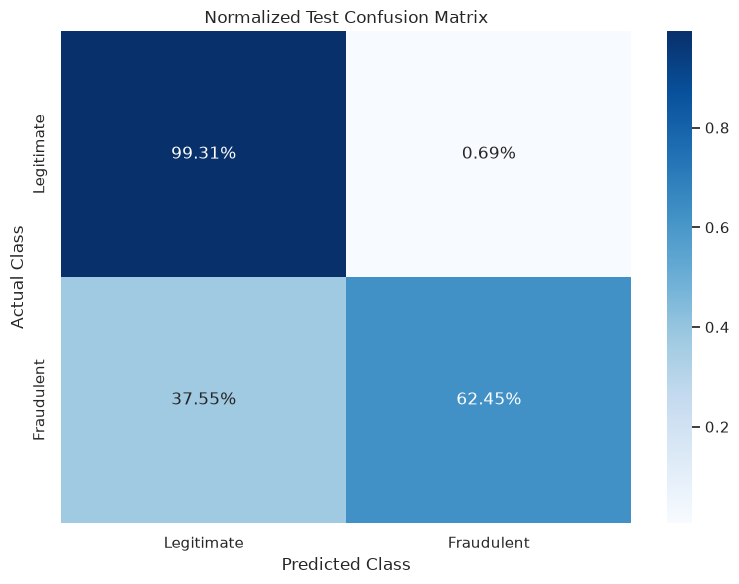

In [57]:
normalized_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1],
    normalize="true"
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Normalized Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

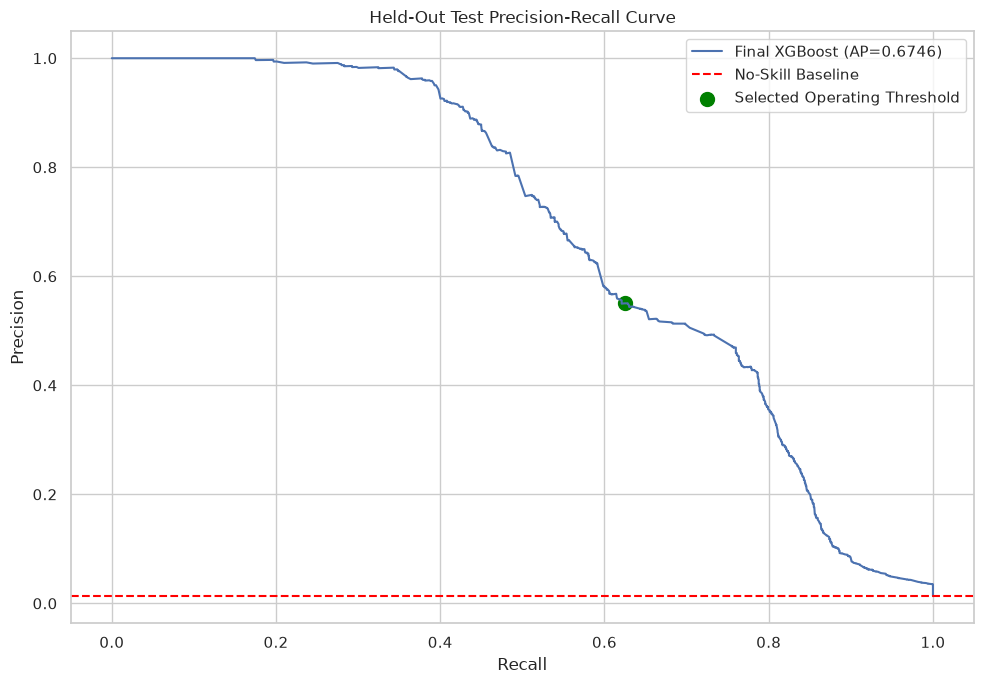

In [58]:
precision, recall, _ = precision_recall_curve(
    y_test,
    test_calibrated_probs
)

test_ap = average_precision_score(
    y_test,
    test_calibrated_probs
)

plt.figure(figsize=(10, 7))

plt.plot(
    recall,
    precision,
    label=f"Final XGBoost (AP={test_ap:.4f})"
)

plt.axhline(
    y_test.mean(),
    color="red",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.scatter(
    final_test_metrics["recall"],
    final_test_metrics["precision"],
    color="green",
    s=100,
    label="Selected Operating Threshold"
)

plt.title("Held-Out Test Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

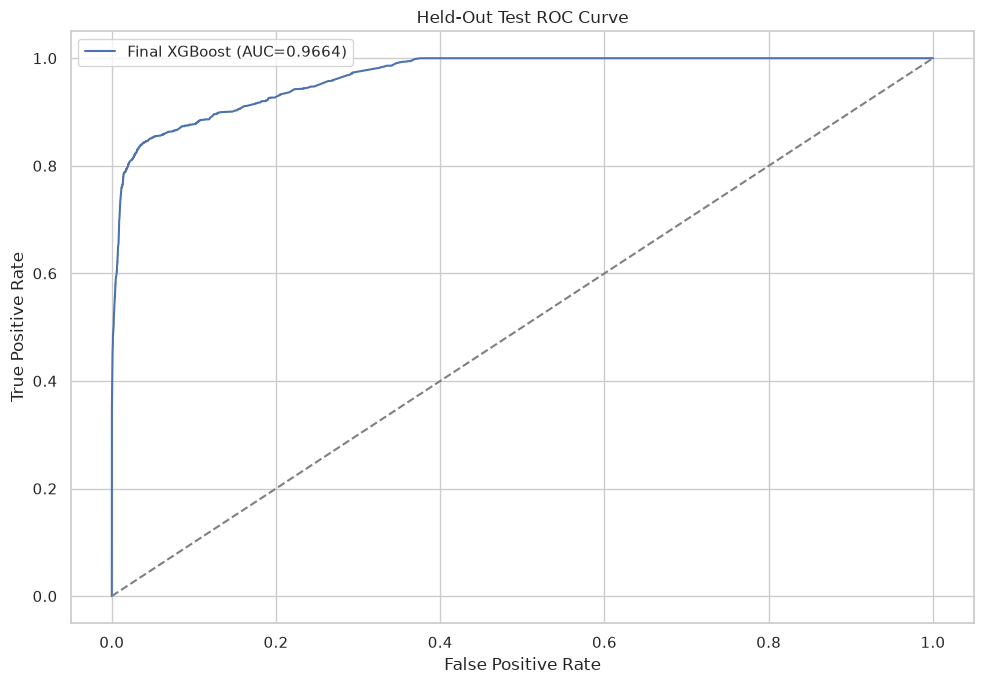

In [59]:
fpr, tpr, _ = roc_curve(
    y_test,
    test_calibrated_probs
)

test_auc = roc_auc_score(
    y_test,
    test_calibrated_probs
)

plt.figure(figsize=(10, 7))

plt.plot(
    fpr,
    tpr,
    label=f"Final XGBoost (AUC={test_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("Held-Out Test ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [60]:
test_calibration_results = pd.DataFrame([
    evaluate_calibration(
        "Original XGBoost",
        y_test,
        test_raw_probs
    ),
    evaluate_calibration(
        "Calibrated XGBoost",
        y_test,
        test_calibrated_probs
    )
])

test_calibration_results.round(6)

,model,average_precision,roc_auc,brier_score,log_loss,mean_predicted_probability,observed_fraud_rate
0,Original XGBoost,0.674554,0.966435,0.009549,0.043910,0.003588,0.013384
1,Calibrated XGBoost,0.674554,0.966435,0.006807,0.028704,0.011793,0.013384


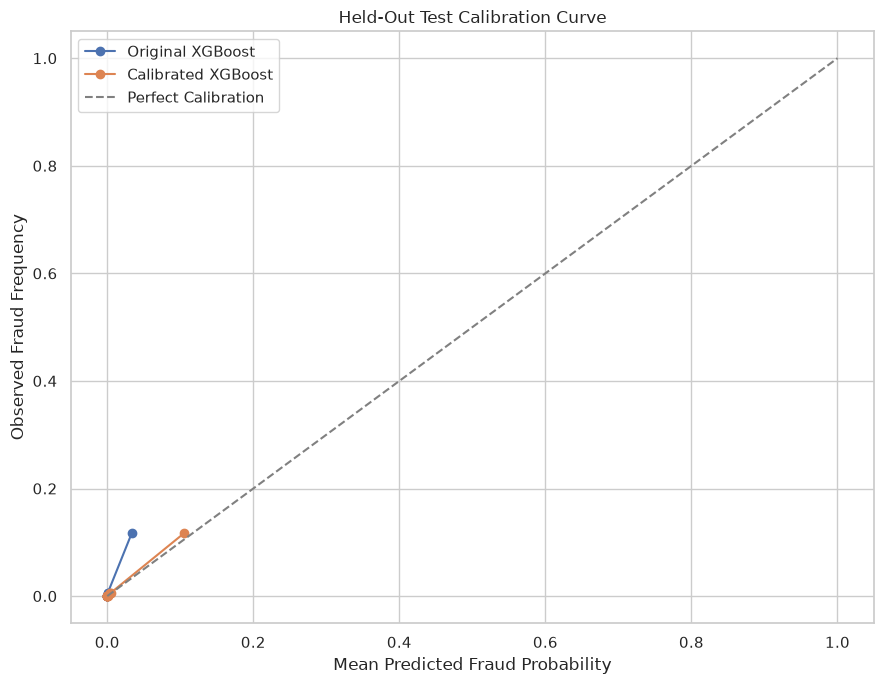

In [61]:
plt.figure(figsize=(9, 7))

for model_name, probabilities in {
    "Original XGBoost": test_raw_probs,
    "Calibrated XGBoost": test_calibrated_probs
}.items():

    observed, predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted,
        observed,
        marker="o",
        label=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.title("Held-Out Test Calibration Curve")
plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Frequency")
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
test_risk_tier_summary = summarize_risk_tiers(
    test_df
)

test_risk_tier_summary

,transactions,fraudulent_transactions,average_probability,total_transaction_amount,fraud_rate,fraudulent_amount,transaction_percentage
risk_tier,,,,,,,
Low Risk,121703,621,0.003905,1.817171e+10,0.005103,1.637681e+08,0.984811
Medium Risk,1512,671,0.413622,2.045354e+09,0.443783,1.141563e+09,0.012235
High Risk,365,362,0.977210,1.418881e+09,0.991781,1.417103e+09,0.002954


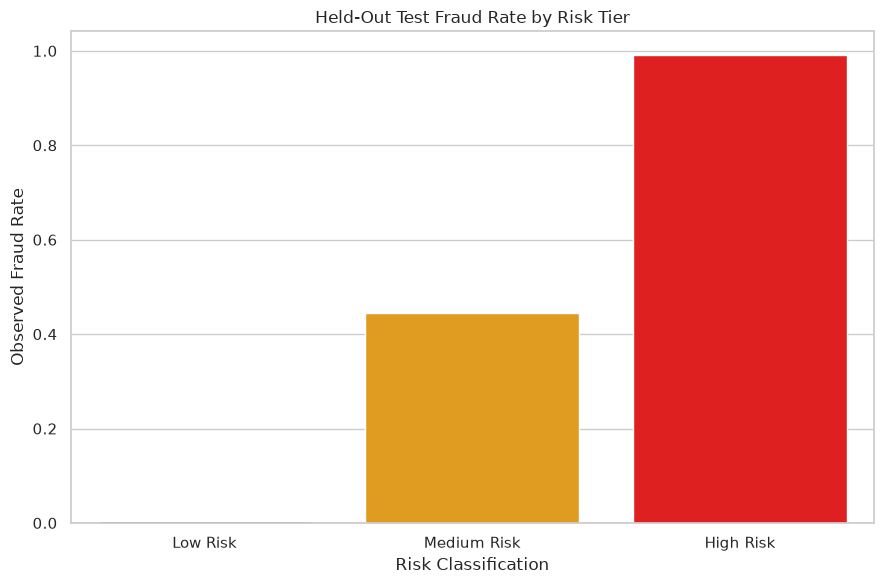

In [63]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=test_risk_tier_summary.reset_index(),
    x="risk_tier",
    y="fraud_rate",
    hue="risk_tier",
    palette={
        "Low Risk": "green",
        "Medium Risk": "orange",
        "High Risk": "red"
    },
    legend=False
)

plt.title("Held-Out Test Fraud Rate by Risk Tier")
plt.xlabel("Risk Classification")
plt.ylabel("Observed Fraud Rate")
plt.tight_layout()
plt.show()

In [64]:
total_test_fraud_amount = test_df.loc[
    y_test == 1,
    "amount"
].sum()

financial_summary = pd.Series({
    "Total Fraudulent Transaction Value":
        total_test_fraud_amount,

    "Detected Fraudulent Transaction Value":
        final_test_metrics["detected_fraud_amount"],

    "Missed Fraudulent Transaction Value":
        final_test_metrics["missed_fraud_amount"],

    "Fraud Value Captured (%)":
        final_test_metrics["fraud_value_captured"] * 100,

    "Investigation Alerts":
        final_test_metrics["alert_count"],

    "Investigation Cost":
        final_test_metrics["investigation_cost"],

    "Missed Preventable Fraud Cost":
        final_test_metrics["missed_fraud_cost"],

    "Total Hypothetical Cost":
        final_test_metrics["total_cost"],

    "Estimated Savings vs. No Detection":
        final_test_metrics["estimated_savings"]
})

financial_summary

Total Fraudulent Transaction Value       2.722435e+09
Detected Fraudulent Transaction Value    2.558666e+09
Missed Fraudulent Transaction Value      1.637681e+08
Fraud Value Captured (%)                 9.398450e+01
Investigation Alerts                     1.877000e+03
Investigation Cost                       1.877000e+05
Missed Preventable Fraud Cost            1.637681e+07
Total Hypothetical Cost                  1.656451e+07
Estimated Savings vs. No Detection       2.556789e+08
dtype: float64

In [65]:
no_detection_cost = (
    total_test_fraud_amount
    * PREVENTABLE_FRAUD_FRACTION
)

final_model_cost = final_test_metrics[
    "total_cost"
]

cost_reduction = (
    (no_detection_cost - final_model_cost)
    / no_detection_cost
)

print(
    f"Hypothetical cost reduction: {cost_reduction:.2%}"
)

Hypothetical cost reduction: 93.92%


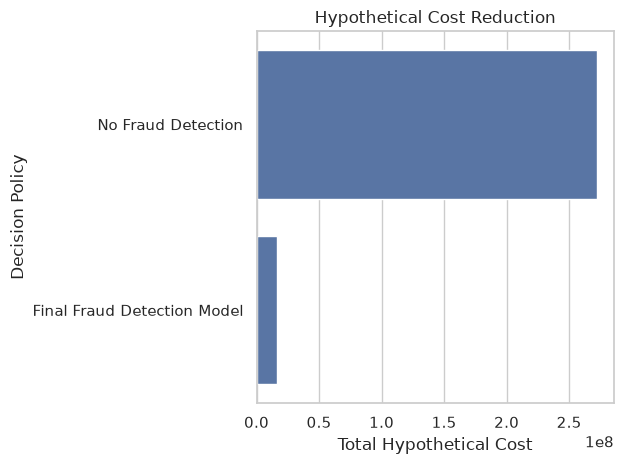

In [66]:
financial_comparison = pd.DataFrame({
    "policy": [
        "No Fraud Detection",
        "Final Fraud Detection Model"
    ],
    "total_cost": [
        no_detection_cost,
        final_model_cost
    ]
})

sns.barplot(
    data=financial_comparison,
    x="total_cost",
    y="policy"
)

plt.title("Hypothetical Cost Reduction")
plt.xlabel("Total Hypothetical Cost")
plt.ylabel("Decision Policy")
plt.tight_layout()
plt.show()

In [67]:
test_df["prediction"] = test_predictions

test_df["prediction_outcome"] = np.select(
    [
        (y_test == 1) & (test_predictions == 1),
        (y_test == 0) & (test_predictions == 1),
        (y_test == 1) & (test_predictions == 0)
    ],
    [
        "True Positive",
        "False Positive",
        "False Negative"
    ],
    default="True Negative"
)

test_df["prediction_outcome"].value_counts()

prediction_outcome
True Negative     121082
True Positive       1033
False Positive       844
False Negative       621
Name: count, dtype: int64

In [68]:
error_summary = test_df.groupby(
    "prediction_outcome"
).agg(
    transactions=("amount", "count"),
    mean_amount=("amount", "mean"),
    median_amount=("amount", "median"),
    total_amount=("amount", "sum"),
    average_fraud_probability=(
        "fraud_probability", "mean"
    ),
    average_recipient_prior_count=(
        "recipient_prior_count", "mean"
    )
)

error_summary

,transactions,mean_amount,median_amount,total_amount,average_fraud_probability,average_recipient_prior_count
prediction_outcome,,,,,,
False Negative,621,2.637168e+05,172915.56,1.637681e+08,0.065982,3.697262
False Positive,844,1.072948e+06,324615.09,9.055684e+08,0.306762,1.800948
True Negative,121082,1.487252e+05,65347.95,1.800795e+10,0.003587,4.970755
True Positive,1033,2.476928e+06,989954.57,2.558666e+09,0.700069,2.210068


In [69]:
fraud_test_df = test_df.loc[
    test_df[target_column] == 1
]

type_performance = fraud_test_df.groupby(
    "type",
    observed=True
).agg(
    fraud_transactions=(target_column, "count"),
    detected_fraud=("prediction", "sum"),
    total_fraud_amount=("amount", "sum")
)

type_performance["recall"] = (
    type_performance["detected_fraud"]
    / type_performance["fraud_transactions"]
)

type_performance

,fraud_transactions,detected_fraud,total_fraud_amount,recall
type,,,,
CASH_OUT,827,437,1.339945e+09,0.528416
TRANSFER,827,596,1.382490e+09,0.720677


In [70]:
recipient_performance = fraud_test_df.groupby(
    "recipient_is_new"
).agg(
    fraud_transactions=(target_column, "count"),
    detected_fraud=("prediction", "sum")
)

recipient_performance["recall"] = (
    recipient_performance["detected_fraud"]
    / recipient_performance["fraud_transactions"]
)

recipient_performance

,fraud_transactions,detected_fraud,recall
recipient_is_new,,,
0,601,299,0.497504
1,1053,734,0.697056


In [71]:
missed_fraud = test_df.loc[
    test_df["prediction_outcome"] == "False Negative"
]

missed_fraud.sort_values(
    "amount",
    ascending=False
)[[
    "step",
    "type",
    "amount",
    "fraud_probability",
    "recipient_is_new",
    "recipient_prior_count",
    "recipient_prior_mean"
]].head(10)

,step,type,amount,fraud_probability,recipient_is_new,recipient_prior_count,recipient_prior_mean
52171,662,TRANSFER,1468304.35,0.142015,1,0,NaN
45401,659,TRANSFER,1467987.57,0.141950,1,0,NaN
69439,686,TRANSFER,1467968.73,0.142015,1,0,NaN
34156,636,TRANSFER,1455839.54,0.141950,1,0,NaN
66382,684,TRANSFER,1430050.84,0.141950,1,0,NaN
25918,613,TRANSFER,1425062.97,0.148879,1,0,NaN
45193,659,TRANSFER,1423627.83,0.141950,1,0,NaN
23237,611,TRANSFER,1418168.85,0.141950,1,0,NaN
71199,686,TRANSFER,1411271.23,0.142015,1,0,NaN
29601,617,TRANSFER,1398166.84,0.140501,1,0,NaN


In [72]:
test_results.to_csv(
    RESULTS_PATH / "final_test_results.csv",
    index=False
)

comparison_df.to_csv(
    RESULTS_PATH / "policy_test_comparison.csv",
    index=False
)

test_calibration_results.to_csv(
    RESULTS_PATH / "test_calibration_results.csv",
    index=False
)

test_risk_tier_summary.to_csv(
    RESULTS_PATH / "test_risk_tier_results.csv"
)

financial_summary.to_csv(
    RESULTS_PATH / "financial_impact_results.csv",
    header=["value"]
)

error_summary.to_csv(
    RESULTS_PATH / "test_error_analysis.csv"
)

type_performance.to_csv(
    RESULTS_PATH / "test_transaction_type_performance.csv"
)

recipient_performance.to_csv(
    RESULTS_PATH / "test_recipient_performance.csv"
)

In [73]:
final_evaluation_metadata = {
    "model_name": advanced_metadata["model_name"],
    "calibration_method": "sigmoid_logit",
    "decision_threshold": float(final_threshold),
    "high_risk_threshold": float(
        final_high_risk_threshold
    ),
    "test_transactions": len(test_df),
    "test_fraudulent_transactions": int(y_test.sum()),
    "test_fraud_rate": float(y_test.mean()),
    "test_average_precision": float(
        final_test_metrics["average_precision"]
    ),
    "test_roc_auc": float(
        final_test_metrics["roc_auc"]
    ),
    "test_precision": float(
        final_test_metrics["precision"]
    ),
    "test_recall": float(
        final_test_metrics["recall"]
    ),
    "test_f1": float(
        final_test_metrics["f1"]
    ),
    "test_fraud_value_captured": float(
        final_test_metrics["fraud_value_captured"]
    ),
    "test_alert_rate": float(
        final_test_metrics["alert_rate"]
    ),
    "hypothetical_estimated_savings": float(
        final_test_metrics["estimated_savings"]
    ),
    "hypothetical_cost_reduction": float(
        cost_reduction
    ),
    "test_set_evaluated": True,
    "policy_frozen_before_test": True,
    "cost_assumptions": "hypothetical"
}

with open(
    MODEL_PATH / "final_evaluation_metadata.json",
    "w"
) as f:

    json.dump(
        final_evaluation_metadata,
        f,
        indent=4
    )

## Key Findings

### Final Model Selection
- Selected the shallow, population-weighted XGBoost model trained using a 10% legitimate transaction sample.
- Retained all 12 leakage-controlled predictive features developed during feature engineering.
- The selected model previously achieved a validation Average Precision of 0.608008.
- Previous supervised modeling experiments demonstrated a 54.18% relative improvement in Average Precision over ordinary logistic regression.
- Previous anomaly detection experiments demonstrated that standalone XGBoost outperformed Isolation Forest, the autoencoder, and all evaluated hybrid configurations.
- Retained standalone XGBoost to avoid unnecessary deployment complexity.
- Reused the previously trained model without retraining its classifier.

### Calibration and Policy Optimization Strategy
- Divided the original chronological validation dataset into separate calibration and policy optimization periods.
- Fitted the probability calibrator using simulation hours 446–519.
- Selected classification thresholds and financial decision policies using simulation hours 520–594.
- Preserved simulation hours 595–743 for final held-out evaluation.

| Dataset | Simulation Hours | Transactions | Fraudulent Transactions | Fraud Rate |
|---|---|---:|---:|---:|
| Calibration | 446–519 | 68,033 | 762 | 1.1200% |
| Policy Optimization | 520–594 | 160,070 | 790 | 0.4935% |
| Held-Out Test | 595–743 | 123,580 | 1,654 | 1.3384% |

- Maintained chronological separation between calibration, policy optimization, and final testing.
- Separating calibration and threshold optimization reduced direct reuse of the same observations for both objectives.
- However, the original validation dataset had previously been used for model selection and early stopping.
- Consequently, calibration and policy optimization results should not be interpreted as fully independent estimates of generalization.
- The classifier, calibrator, financial assumptions, and decision thresholds were finalized before held-out test evaluation.

### Probability Calibration Performance
- Implemented sigmoid probability calibration using logistic regression fitted on the log-odds of the original XGBoost predictions.
- Fitted the calibration model without majority-class undersampling or class weighting.
- Learned the following calibration parameters:
  - Calibration coefficient: 1.180470
  - Calibration intercept: 3.087733
- The positive calibration coefficient preserved the original model's fraud-risk ranking.

#### Policy Optimization Calibration Results

| Metric | Original XGBoost | Calibrated XGBoost |
|---|---:|---:|
| Average Precision | 0.577365 | 0.577365 |
| ROC-AUC | 0.968702 | 0.968702 |
| Brier Score | 0.003619 | 0.003012 |
| Log Loss | 0.016727 | 0.013966 |
| Mean Predicted Probability | 0.1676% | 0.7388% |
| Observed Fraud Rate | 0.4935% | 0.4935% |

- Probability calibration reduced the Brier score by approximately 16.77%.
- Probability calibration reduced log loss by approximately 16.51%.
- Average Precision and ROC-AUC remained unchanged because the calibration transformation preserved score ordering.
- The original model underestimated the average fraud probability.
- The calibrated model overestimated the average fraud probability during the policy optimization period.
- Despite this aggregate overestimation, calibration improved both evaluated probabilistic scoring metrics.
- Differences in fraud prevalence between the calibration and policy optimization periods may contribute to residual calibration error.

### Impact of Calibration on Classification Performance
- Evaluated original and calibrated XGBoost predictions using the same default classification threshold of 0.5.

| Metric | Original XGBoost | Calibrated XGBoost |
|---|---:|---:|
| Precision | 97.52% | 80.39% |
| Recall | 14.94% | 42.03% |
| F1-score | 0.259056 | 0.551953 |
| Investigation Alerts | 121 | 413 |
| True Positives | 118 | 332 |
| False Positives | 3 | 81 |
| Fraud Value Captured | 37.41% | 64.18% |

- Calibration increased the number of transactions exceeding the default classification threshold.
- Recall increased substantially while precision decreased.
- Fraudulent transaction value captured increased by approximately 26.77 percentage points.
- These findings demonstrate that probability calibration can significantly affect threshold-dependent decisions without improving the underlying ranking performance.
- Calibration and classification threshold optimization should therefore be treated as related but distinct objectives.

### Classification Threshold Analysis
- Implemented an efficient threshold evaluation algorithm using sorted probabilities and cumulative statistics.
- Evaluated distinct probability boundaries instead of relying on an arbitrary fixed threshold grid.
- Preserved consistent classification decisions for transactions with identical predicted probabilities.
- Evaluated precision, recall, F1-score, investigation workload, and fraudulent transaction value captured across candidate thresholds.

The threshold maximizing F1-score was approximately 0.383153.

Maximum-F1 policy performance:
- Precision: 73.62%
- Recall: 47.34%
- F1-score: 0.576271
- Investigation alerts: 508
- Investigation rate: 0.3174%
- True positives: 374
- False positives: 134
- Fraudulent transaction value captured: 72.60%

- Maximizing F1-score provided a useful statistical benchmark.
- However, F1-score does not directly account for transaction value, investigation costs, or operational capacity.
- Additional financial optimization was therefore necessary.

### Financial Cost-Sensitive Optimization
- Developed a hypothetical financial cost framework to evaluate fraud investigation policies.
- Assigned an investigation cost to every flagged transaction, including both fraudulent and legitimate transactions.
- Defined missed fraud cost using an assumed preventable fraction of missed fraudulent transaction value.

The primary financial assumptions were:
- Investigation cost: 100 monetary units per flagged transaction.
- Preventable fraud value fraction: 10%.
- Maximum investigation rate during policy optimization: 1%.

The hypothetical objective function was:

$$
C(t) = cA(t) + rV_{\text{missed}}(t)
$$

Where:
- $t$ is the classification threshold.
- $c$ is the investigation cost per alert.
- $A(t)$ is the number of investigation alerts.
- $r$ is the assumed preventable fraction of fraudulent transaction value.
- $V_{\text{missed}}(t)$ is the total value of missed fraudulent transactions.

- The unconstrained financial cost-optimal threshold was approximately 0.011773.
- This threshold achieved:
  - Precision: 9.08%
  - Recall: 86.46%
  - Investigation alerts: 7,525
  - Investigation rate: 4.7011%
  - Fraudulent transaction value captured: 98.33%
  - Total hypothetical cost: approximately 2.31 million monetary units
- Although financially attractive under the assumed cost structure, the unconstrained threshold exceeded the specified investigation capacity.
- These findings demonstrate the importance of combining financial objectives with operational constraints.

### Investigation Capacity Constraints
- Restricted threshold selection to configurations flagging no more than 1% of policy optimization transactions.
- Selected a capacity-constrained minimum-cost threshold of approximately 0.161681.
- The selected policy achieved:
  - Precision: 32.25%
  - Recall: 65.06%
  - F1-score: 0.431208
  - Investigation alerts: 1,594
  - Investigation rate: 0.9958%
  - True positives: 514
  - False positives: 1,080
  - False negatives: 276
  - Fraudulent transaction value captured: 92.99%
  - Total hypothetical cost: approximately 6.70 million monetary units
  - Estimated savings relative to no detection: approximately 86.56 million monetary units
- The selected policy satisfied the investigation capacity constraint during policy optimization.
- The constrained threshold sacrificed some financial detection performance relative to the unconstrained threshold while substantially reducing investigation workload.
- The capacity-constrained policy was selected as the final operational configuration.

### Decision Policy Comparison

| Decision Policy | Threshold | Precision | Recall | F1-score | Alert Rate | Fraud Value Captured | Hypothetical Cost |
|---|---:|---:|---:|---:|---:|---:|---:|
| No Detection | >1.0 | 0.00% | 0.00% | 0.000000 | 0.0000% | 0.00% | 93.26M |
| Default Threshold | 0.500000 | 80.39% | 42.03% | 0.551953 | 0.2580% | 64.18% | 33.45M |
| Maximum F1 | 0.383153 | 73.62% | 47.34% | 0.576271 | 0.3174% | 72.60% | 25.60M |
| Minimum Cost | 0.011773 | 9.08% | 86.46% | 0.164281 | 4.7011% | 98.33% | 2.31M |
| Capacity-Constrained Minimum Cost | 0.161681 | 32.25% | 65.06% | 0.431208 | 0.9958% | 92.99% | 6.70M |

- Different optimization objectives produced substantially different classification thresholds.
- The maximum-F1 threshold did not minimize hypothetical financial costs.
- The unconstrained minimum-cost threshold achieved the strongest financial performance but exceeded investigation capacity.
- The capacity-constrained minimum-cost threshold provided a compromise between financial detection performance and operational workload.
- These findings demonstrate that the optimal decision threshold depends on the intended business objective.

### Financial Cost Sensitivity Analysis
- Evaluated the robustness of the selected decision policy under alternative financial assumptions.
- Tested investigation costs of 10, 50, 100, 500, and 1,000 monetary units per alert.
- Tested preventable fraud value fractions of 1%, 5%, 10%, 25%, 50%, and 100%.
- Evaluated 30 hypothetical financial scenarios.
- Maintained the 1% investigation capacity constraint across all scenarios.
- Optimal thresholds ranged from approximately 0.161681 to 0.280964.
- Optimal investigation rates ranged from approximately 0.5610% to 0.9958%.
- Higher investigation costs generally encouraged more selective investigation policies.
- Higher preventable fraud value fractions generally justified investigating more transactions.
- Many scenarios selected the same threshold of approximately 0.161681, suggesting that investigation capacity was frequently the dominant constraint.

Selected sensitivity analysis results:

| Investigation Cost | Preventable Fraction | Optimal Threshold | Alert Rate | Fraud Value Captured |
|---:|---:|---:|---:|---:|
| 10 | 10% | 0.161681 | 0.9958% | 92.99% |
| 100 | 10% | 0.161681 | 0.9958% | 92.99% |
| 500 | 10% | 0.165959 | 0.9802% | 92.98% |
| 1,000 | 10% | 0.165959 | 0.9802% | 92.98% |
| 1,000 | 1% | 0.280964 | 0.5610% | 88.72% |

- The primary financial assumptions were retained rather than selecting an alternative scenario based on more favorable reported performance.
- Financial sensitivity analysis demonstrates how the decision policy may adapt to different hypothetical business environments.
- Actual deployment would require institution-specific investigation costs, prevention effectiveness, and operational constraints.

### Risk Classification Tiers
- Implemented a three-tier fraud risk classification system.
- Used the capacity-constrained threshold as the boundary for investigation.
- Selected a stricter high-risk threshold using a target investigation rate of 0.1% during policy optimization.

The finalized risk thresholds were:
- Low Risk: probability below 0.161681
- Medium Risk: probability at or above 0.161681 and below 0.927988
- High Risk: probability at or above 0.927988

#### Policy Optimization Risk Tier Results

| Risk Tier | Transactions | Fraudulent Transactions | Mean Predicted Probability | Observed Fraud Rate |
|---|---:|---:|---:|---:|
| Low Risk | 158,476 | 276 | 0.3289% | 0.1742% |
| Medium Risk | 1,434 | 362 | 35.2623% | 25.2441% |
| High Risk | 160 | 152 | 97.3106% | 95.0000% |

- Observed fraud prevalence increased substantially across the three assigned risk categories.
- The high-risk category contained 152 fraudulent transactions and only eight legitimate transactions.
- The risk classification system provides more actionable information than a binary fraud prediction alone.
- Medium-risk transactions can be assigned to standard investigation workflows.
- High-risk transactions can be prioritized for investigation.
- Automatic transaction blocking was not implemented.

### Final Held-Out Test Performance
- Evaluated the finalized XGBoost model on the previously unused test period spanning simulation hours 595–743.
- Reloaded the serialized deployment artifact to verify that the fitted preprocessing pipeline, classifier, calibrator, and decision thresholds could be used for inference.
- The test dataset contains 123,580 transactions, including 1,654 fraudulent transactions.
- The observed test fraud prevalence was approximately 1.3384%.

Final held-out test performance:

| Metric | Result |
|---|---:|
| Average Precision | 0.674554 |
| ROC-AUC | 0.966435 |
| Accuracy | 98.8145% |
| Precision | 55.0346% |
| Recall | 62.4547% |
| F1-score | 0.585103 |
| Investigation Alerts | 1,877 |
| Investigation Rate | 1.5189% |
| Fraudulent Transaction Value Captured | 93.9845% |
| Decision Threshold | 0.161681 |

Final confusion matrix:

| Actual Class | Predicted Legitimate | Predicted Fraudulent |
|---|---:|---:|
| Legitimate | 121,082 | 844 |
| Fraudulent | 621 | 1,033 |

- Correctly identified 1,033 fraudulent transactions.
- Generated 844 false-positive investigation alerts.
- Missed 621 fraudulent transactions.
- Correctly classified 121,082 legitimate transactions.
- The finalized model demonstrated strong ranking performance on the held-out temporal test dataset.
- No classification threshold or calibration parameters were adjusted using the test results.

### Comparison Against Default Classification Policies

| Model or Policy | Precision | Recall | F1-score | Alert Rate | Fraud Value Captured |
|---|---:|---:|---:|---:|---:|
| Original XGBoost - Default Threshold | 99.66% | 17.65% | 0.299949 | 0.2371% | 45.72% |
| Calibrated XGBoost - Default Threshold | 88.92% | 43.65% | 0.585564 | 0.6571% | 75.63% |
| Final XGBoost | 55.03% | 62.45% | 0.585103 | 1.5189% | 93.98% |
| PaySim Fraud Rule | 100.00% | 0.48% | 0.009627 | 0.0065% | 1.56% |

- Probability calibration substantially improved recall and fraudulent transaction value captured at the default classification threshold.
- Cost-sensitive threshold optimization produced additional improvements in fraud recall and fraudulent transaction value captured.
- The finalized decision policy improved fraud value captured by approximately 48.26 percentage points relative to the original XGBoost default threshold.
- The finalized model improved fraud value captured by approximately 18.35 percentage points relative to calibrated XGBoost at the default threshold.
- The final decision policy achieved a slightly lower F1-score than calibrated XGBoost at the default threshold.
- However, the final policy achieved substantially lower hypothetical financial costs.
- The existing PaySim fraud rule demonstrated perfect precision but extremely limited fraud detection coverage.
- These results demonstrate that financial decision-making objectives may favor different operating thresholds than conventional classification metrics.

### Generalization Under Temporal Distribution Shift

| Metric | Policy Optimization | Held-Out Test |
|---|---:|---:|
| Fraud Prevalence | 0.4935% | 1.3384% |
| Average Precision | 0.577365 | 0.674554 |
| ROC-AUC | 0.968702 | 0.966435 |
| Precision | 32.25% | 55.03% |
| Recall | 65.06% | 62.45% |
| F1-score | 0.431208 | 0.585103 |
| Investigation Rate | 0.9958% | 1.5189% |
| Fraud Value Captured | 92.99% | 93.98% |

- Average Precision increased from 0.577365 during policy optimization to 0.674554 on held-out test data.
- ROC-AUC remained relatively stable across the two evaluation periods.
- Precision and F1-score increased on the test dataset.
- Recall decreased slightly.
- Fraudulent transaction value captured increased by approximately one percentage point.
- Fraud prevalence was substantially higher during the test period than during policy optimization.
- Average Precision depends partly on class prevalence, so improved test Average Precision does not necessarily indicate stronger discrimination under otherwise identical conditions.
- Changes in transaction distributions and fraud prevalence may affect the operational behavior of fixed decision thresholds.

### Investigation Capacity Generalization
- The selected threshold satisfied the 1% investigation capacity target during policy optimization.
- The same frozen threshold produced an investigation rate of 1.5189% on the held-out test dataset.
- The test investigation workload exceeded the original target by approximately 0.52 percentage points.
- Consequently, the original capacity target was not satisfied during final testing.
- Selecting a threshold under a historical capacity constraint does not guarantee that the constraint will remain satisfied under future distribution shifts.
- This represents an operational limitation of fixed probability thresholds.
- The classification threshold was not adjusted using the held-out test dataset.
- Future deployment strategies should investigate:
  - Capacity-aware investigation queues.
  - Time-window-based alert prioritization.
  - Monitoring changes in predicted risk distributions.
  - Periodic probability recalibration.
  - Threshold updates using newly available labeled development data.
- Any adaptive decision policy should be evaluated on a separate future evaluation period.

### Final Probability Calibration Performance

| Metric | Original XGBoost | Calibrated XGBoost |
|---|---:|---:|
| Average Precision | 0.674554 | 0.674554 |
| ROC-AUC | 0.966435 | 0.966435 |
| Brier Score | 0.009549 | 0.006807 |
| Log Loss | 0.043910 | 0.028704 |
| Mean Predicted Probability | 0.3588% | 1.1793% |
| Observed Fraud Rate | 1.3384% | 1.3384% |

- Probability calibration reduced the held-out test Brier score by approximately 28.71%.
- Probability calibration reduced held-out test log loss by approximately 34.63%.
- The calibrated model produced a mean predicted fraud probability substantially closer to the observed test fraud prevalence.
- Calibration preserved Average Precision and ROC-AUC.
- These findings indicate that the fitted calibration transformation improved probabilistic predictions on future transactions despite temporal distribution shift.
- Some underestimation of aggregate fraud probability remained.
- Probability calibration should therefore be monitored after deployment rather than assumed to remain permanently reliable.

### Final Risk Tier Performance

| Risk Tier | Transactions | Fraudulent Transactions | Mean Predicted Probability | Observed Fraud Rate |
|---|---:|---:|---:|---:|
| Low Risk | 121,703 | 621 | 0.3905% | 0.5103% |
| Medium Risk | 1,512 | 671 | 41.3622% | 44.3783% |
| High Risk | 365 | 362 | 97.7210% | 99.1781% |

- Observed fraud prevalence increased monotonically across the three risk categories.
- The low-risk category contained approximately 98.48% of all test transactions.
- The medium-risk category exhibited an observed fraud rate of approximately 44.38%.
- The high-risk category exhibited an observed fraud rate of approximately 99.18%.
- Only three legitimate transactions were assigned to the high-risk category.
- The combined medium-risk and high-risk categories identified 1,033 fraudulent transactions.
- The high-risk category captured approximately 1.42 billion monetary units in fraudulent transaction value.
- The high-risk investigation rate increased to approximately 0.2954%, exceeding the original policy optimization target of 0.1%.
- The risk tiers demonstrated meaningful fraud discrimination but remained sensitive to temporal changes in transaction distributions.
- Risk classification provides a practical foundation for prioritized investigation and dashboard-based monitoring.

### Fraudulent Transaction Value Captured
- The total fraudulent transaction value in the held-out test dataset was approximately 2.72 billion monetary units.
- The finalized decision policy detected approximately 2.56 billion monetary units in fraudulent transaction value.
- Approximately 163.77 million monetary units in fraudulent transaction value remained undetected.
- The finalized model captured approximately 93.98% of total fraudulent transaction value.
- The model identified approximately 62.45% of fraudulent transactions by count.
- The substantially higher value-based detection rate indicates that the model was more successful at identifying higher-value fraudulent transactions.
- Evaluating fraudulent transaction value provides important financial context beyond transaction-level classification metrics.
- Detected fraudulent transaction value should not be interpreted directly as realized financial losses prevented.

### Hypothetical Financial Impact
- Evaluated the finalized model using the financial assumptions established before test evaluation.
- Assigned an investigation cost of 100 monetary units to each flagged transaction.
- Assumed that investigating a fraudulent transaction prevents 10% of its transaction value from becoming a financial loss.

| Financial Metric | Held-Out Test Result |
|---|---:|
| Total Fraudulent Transaction Value | 2,722,434,569.36 |
| Detected Fraudulent Transaction Value | 2,558,666,443.67 |
| Missed Fraudulent Transaction Value | 163,768,125.69 |
| Investigation Alerts | 1,877 |
| Investigation Cost | 187,700.00 |
| Missed Preventable Fraud Cost | 16,376,812.57 |
| Total Hypothetical Cost | 16,564,512.57 |
| Estimated Savings vs. No Detection | 255,678,944.37 |
| Hypothetical Cost Reduction | 93.92% |

#### Financial Cost Comparison

| Decision Policy | Hypothetical Total Cost |
|---|---:|
| No Detection | 272.24M |
| PaySim Fraud Rule | 267.99M |
| Original XGBoost - Default Threshold | 147.79M |
| Calibrated XGBoost - Default Threshold | 66.43M |
| Final XGBoost | 16.56M |

- The finalized decision policy reduced hypothetical financial costs by approximately 93.92% relative to no fraud detection.
- The optimized policy achieved substantially lower hypothetical costs than both original and calibrated XGBoost at the default threshold.
- Financial improvements were achieved by increasing the detection of higher-value fraudulent transactions.
- The financial results depend directly on the assumed investigation cost and preventable fraud value fraction.
- These figures represent simulated financial outcomes rather than actual monetary savings.
- PaySim does not provide verified fraud prevention effectiveness, recovery rates, or institution-specific operating costs.

### Model Error Analysis

#### Transaction Characteristics by Prediction Outcome

| Prediction Outcome | Transactions | Mean Transaction Amount | Median Transaction Amount |
|---|---:|---:|---:|
| True Negative | 121,082 | 148,725 | 65,347.95 |
| True Positive | 1,033 | 2,476,928 | 989,954.57 |
| False Positive | 844 | 1,072,948 | 324,615.09 |
| False Negative | 621 | 263,717 | 172,915.56 |

- Correctly identified fraudulent transactions had substantially higher average transaction amounts than missed fraudulent transactions.
- The average transaction amount of correctly detected fraud was approximately 9.4 times greater than that of missed fraud.
- False-positive transactions also exhibited relatively high transaction amounts.
- These findings suggest that transaction amount and related behavioral patterns contribute substantially to fraud-risk scoring.
- Missed fraudulent transactions had an average predicted fraud probability of approximately 0.065982.
- False-positive transactions had an average predicted fraud probability of approximately 0.306762.
- Correctly detected fraudulent transactions had an average predicted probability of approximately 0.700069.
- Correctly classified legitimate transactions had an average predicted probability of approximately 0.003587.

#### Fraud Recall by Transaction Type

| Transaction Type | Fraudulent Transactions | Detected Fraud | Recall |
|---|---:|---:|---:|
| CASH_OUT | 827 | 437 | 52.84% |
| TRANSFER | 827 | 596 | 72.07% |

- The model achieved substantially higher recall for fraudulent TRANSFER transactions than fraudulent CASH_OUT transactions.
- TRANSFER fraud recall exceeded CASH_OUT fraud recall by approximately 19.23 percentage points.
- These results are consistent with previous modeling experiments demonstrating differences in fraud detection across transaction categories.
- Transaction-type-specific evaluation reveals weaknesses that aggregate performance metrics may conceal.

#### Fraud Recall by Recipient History

| Recipient Status | Fraudulent Transactions | Detected Fraud | Recall |
|---|---:|---:|---:|
| Existing Recipient | 601 | 299 | 49.75% |
| New Recipient | 1,053 | 734 | 69.71% |

- The model achieved higher fraud recall for transactions involving new recipients.
- Recall for new recipients exceeded recall for existing recipients by approximately 19.96 percentage points.
- Historical recipient behavior remains important for understanding model strengths and weaknesses.
- Fraud involving existing recipients represents a potential area for future research.

#### High-Value Missed Fraud
- Investigated the ten highest-value fraudulent transactions missed by the final decision policy.
- All ten transactions were TRANSFER transactions involving new recipients.
- Transaction amounts ranged from approximately 1.40 million to 1.47 million monetary units.
- Predicted fraud probabilities ranged from approximately 0.1405 to 0.1489.
- These transactions received risk scores below the selected investigation threshold of approximately 0.161681.
- The cases illustrate how relatively high-value fraudulent transactions can remain undetected when their predicted probabilities fall below a fixed threshold.
- These examples provide useful candidates for transaction-level SHAP analysis.
- A future decision policy could investigate transaction-specific expected financial loss rather than relying exclusively on probability thresholds.
- No model or threshold adjustments were performed using these held-out test findings.

### Operational and Model Limitations
- PaySim is a synthetic financial transaction dataset and may not adequately represent real-world fraud behavior.
- Financial cost assumptions are hypothetical and are not based on verified financial institution operating costs.
- Detected fraudulent transaction value does not necessarily equal preventable financial losses.
- The calibration and policy optimization datasets were previously included in the validation period used for model selection.
- The fitted probability calibrator may deteriorate under future changes in fraud prevalence and transaction characteristics.
- A fixed probability threshold does not guarantee consistent investigation workload.
- The finalized policy exceeded the original 1% investigation capacity target on the held-out test dataset.
- The high-risk tier also exceeded its original policy optimization investigation-rate target.
- Financial threshold optimization used historical transaction outcomes rather than a live investigation environment.
- The selected probability threshold does not explicitly account for individual transaction value when making each classification decision.
- The model exhibited different fraud recall rates across transaction types and recipient history groups.
- Some high-value fraudulent transactions remained undetected.
- No automatic transaction blocking, real-world intervention, or actual financial recovery was evaluated.
- The held-out test dataset should not be reused for subsequent model tuning while continuing to report its performance as an independent evaluation.

### Model Artifacts and Reproducibility
- Saved the final XGBoost classifier, preprocessing pipeline, sigmoid probability calibrator, and risk thresholds together in a serialized deployment artifact.
- Successfully reloaded the final deployment artifact before held-out test inference.
- Preserved feature definitions, model configuration, calibration parameters, financial assumptions, and classification thresholds.
- Exported the final decision policy metadata and held-out evaluation metadata.
- Exported the following evaluation results:
  - Probability calibration results.
  - Decision policy comparison results.
  - Financial cost sensitivity results.
  - Policy optimization risk tier results.
  - Held-out test classification results.
  - Policy optimization and test performance comparisons.
  - Held-out test calibration results.
  - Held-out test risk tier results.
  - Hypothetical financial impact results.
  - Prediction error analysis.
  - Transaction-type-specific fraud detection performance.
  - Recipient-history-specific fraud detection performance.
- Maintained chronological evaluation procedures and consistent random seeds.
- Preserved the finalized decision policy before evaluating the held-out test dataset.
- All notebook code cells executed without recorded errors.

### Implications for Production Deployment
- Retain the finalized calibrated XGBoost pipeline as the primary fraud detection model.
- Use the selected threshold of approximately 0.161681 as the initial model-triggered investigation boundary.
- Use the high-risk threshold of approximately 0.927988 for prioritized investigation.
- Provide calibrated fraud probabilities and risk classifications through the future prediction API.
- Maintain separate financial, statistical, and operational performance metrics.
- Monitor investigation volume to identify violations of operational capacity targets.
- Consider capacity-aware alert prioritization rather than relying exclusively on fixed thresholds.
- Investigate transaction-specific expected financial loss using predicted fraud probability and transaction amount.
- Monitor probability calibration, fraud prevalence, feature distributions, and prediction score distributions over time.
- Introduce explainability through global and transaction-level SHAP analysis.
- Investigate the model's behavior on high-value false-negative and false-positive transactions.
- Evaluate temporal robustness and distribution shift before implementing automated retraining.
- Use newly available labeled development data and separate future evaluation periods for subsequent model improvements.
- Treat the current system as an experimental fraud risk decision-support platform rather than a validated real-world financial intervention system.

## Conclusion

The model evaluation phase transformed the previously trained XGBoost classifier into a calibrated, cost-sensitive fraud risk decision-making system.

Sigmoid probability calibration improved probabilistic prediction quality while preserving Average Precision and ROC-AUC. On held-out test data, calibration reduced the Brier score by approximately 28.71% and log loss by approximately 34.63%.

Financial threshold optimization identified a capacity-constrained decision threshold of approximately 0.161681. The selected policy balanced fraudulent transaction value captured against hypothetical investigation costs while satisfying a 1% investigation capacity constraint during policy optimization.

On the chronological held-out test dataset containing 123,580 transactions, the finalized model achieved:
- Average Precision of 0.674554.
- ROC-AUC of 0.966435.
- Precision of 55.03%.
- Recall of 62.45%.
- F1-score of 0.585103.
- Fraudulent transaction value captured of 93.98%.

Under the predefined hypothetical financial assumptions, the finalized decision policy reduced total financial costs by approximately 93.92% relative to no fraud detection.

The three-tier risk classification system demonstrated meaningful fraud discrimination, with the high-risk category achieving an observed fraud rate of approximately 99.18%.

However, the frozen classification threshold produced an investigation rate of approximately 1.52% on the held-out test dataset, exceeding the original 1% capacity target. This finding highlights the operational challenges associated with temporal distribution shift and fixed classification thresholds.

Overall, the evaluation demonstrates the importance of combining predictive modeling, probability calibration, financial optimization, operational constraints, and rigorous held-out evaluation when developing a fraud detection decision-support system.

The next phase will investigate global and transaction-level model explainability using SHAP, followed by temporal robustness evaluation and distribution shift analysis.